In [2]:
import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import time
SCRIPT_START = time.time()     # start the clock for the whole notebook

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Connect Google Drive (only in Colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR        = "/content/drive/MyDrive/Colab Notebooks/Thesis/"
ZIP_DIR         = BASE_DIR + "data/Zip/"                                   # sample_YYYY.zip from Freddie Mac
CHECKPOINT_PATH = BASE_DIR + "data/results/merged_loans_checkpoint.csv"    # one row per loan, with DEFAULT_FLAG
CHECKS_PATH     = BASE_DIR + "data/results/eda/raw_file_checks.csv"        # file checks per origination year
TIMING_PATH     = BASE_DIR + "data/results/eda/first_default_month.csv"    # month of first default

VINTAGES = list(range(1999, 2021))       # origination years 1999-2020
HORIZON_MONTHS = 60                      # default window: the first 60 months of each loan
TARGET = "DEFAULT_FLAG"
YEAR = "sample_vintage_year"

ORIG_COLUMNS = [
    "credit_score_classic_fico", "first_payment_date", "first_time_homebuyer_indicator", "maturity_date",
    "msa_or_metropolitan_division", "mi_percent", "number_of_units", "occupancy_status", "original_cltv",
    "original_dti", "original_upb", "original_ltv", "original_interest_rate", "channel",
    "prepayment_penalty_indicator", "amortization_type", "property_state", "property_type", "postal_code",
    "loan_identifier", "loan_purpose", "original_loan_term", "number_of_borrowers", "seller_name",
    "super_conforming_flag", "pre_harp_loan_sequence_number", "special_eligibility_program",
    "harp_indicator", "property_valuation_method", "interest_only_indicator", "vantage_score_4_0",
]
PERF_COLUMNS = [
    "loan_identifier", "period", "current_actual_upb", "current_loan_delinquency_status", "loan_age",
    "remaining_months_to_legal_maturity", "defect_settlement_date", "modification_flag",
    "zero_balance_code", "zero_balance_effective_date", "current_interest_rate",
    "current_non_interest_bearing_upb", "due_date_of_last_paid_installment", "mi_recoveries",
    "net_sale_proceeds", "non_mi_recoveries", "total_expenses", "legal_costs",
    "maintenance_and_preservation_costs", "taxes_and_insurance", "miscellaneous_expenses", "actual_loss",
    "cumulative_modification_costs", "interest_rate_step_indicator", "payment_deferral_flag",
    "estimated_loan_to_value_eltv", "zero_balance_removal_upb", "delinquent_accrued_interest",
    "delinquency_due_to_disaster", "borrower_assistance_plan", "current_period_modification_costs",
    "current_interest_bearing_upb", "mi_cancellation_indicator", "servicer_name", "bankruptcy_cramdown_costs",
]

PERF_USED = ["loan_identifier", "period", "loan_age", "current_loan_delinquency_status", "zero_balance_code"]


def is_default_event(perf):
    # 90+ days past due (status 3 or higher, or R = REO acquisition) or a credit-event termination
    status = perf["current_loan_delinquency_status"].astype(str).str.strip().str.upper()
    past_due_90 = (status == "R") | (pd.to_numeric(status, errors="coerce") >= 3)
    code = perf["zero_balance_code"].astype(str).str.extract(r"(\d+)")[0].str.zfill(2)
    return past_due_90 | code.isin(["02", "03", "09"])


def build_year(year):
    # Read both files from the ZIP (the raw files have no header row)
    with zipfile.ZipFile(ZIP_DIR + f"sample_{year}.zip") as z:
        names = [n for n in z.namelist() if n.lower().endswith(".txt")]
        orig_name = [n for n in names if "orig" in n.lower()][0]
        perf_name = [n for n in names if "orig" not in n.lower()][0]
        orig = pd.read_csv(z.open(orig_name), sep="|", header=None, names=ORIG_COLUMNS, low_memory=False)
        perf = pd.read_csv(z.open(perf_name), sep="|", header=None, names=PERF_COLUMNS,
                           usecols=PERF_USED, dtype=str)
    perf["loan_age"] = pd.to_numeric(perf["loan_age"], errors="coerce")
    perf["event"] = is_default_event(perf)

    # Default label: any default event within the first 60 months
    first_60 = perf[perf["loan_age"] <= HORIZON_MONTHS]
    per_loan = first_60.groupby("loan_identifier").agg(DEFAULT_FLAG=("event", "max"),
                                                       n_performance_months=("event", "size"))
    loans = orig.merge(per_loan, left_on="loan_identifier", right_index=True, how="left")
    loans["DEFAULT_FLAG"] = (loans["DEFAULT_FLAG"] == True).astype(int)        # no records -> 0
    loans["n_performance_months"] = loans["n_performance_months"].fillna(0).astype(int)
    loans[YEAR] = year

    # File checks: are the two files linked, and how long are loans followed?
    orig_ids = set(orig["loan_identifier"])
    perf_ids = set(perf["loan_identifier"])
    checks = {"vintage": year,
              "orig_loans": len(orig_ids),
              "perf_loans": len(perf_ids),
              "in_perf_not_in_orig": len(perf_ids - orig_ids),
              "in_orig_not_in_perf": len(orig_ids - perf_ids),
              "records_per_loan": round(len(perf) / len(perf_ids), 1),
              "last_month": pd.to_datetime(perf["period"], format="%Y%m").max().strftime("%Y-%m")}

    # Month of the first default event over the whole observed loan life (no 60-month cap)
    first = perf[perf["event"]].groupby("loan_identifier")["loan_age"].min()
    timing = pd.DataFrame({"loan_identifier": first.index, "months_to_default": first.values, "vintage": year})
    print(f"{year}: {len(loans):,} loans, default rate {loans['DEFAULT_FLAG'].mean():.2%}")
    return loans, checks, timing


if os.path.exists(CHECKPOINT_PATH) and os.path.exists(CHECKS_PATH) and os.path.exists(TIMING_PATH):
    df = pd.read_csv(CHECKPOINT_PATH, low_memory=False)
    file_checks = pd.read_csv(CHECKS_PATH, index_col="vintage")
    first_default = pd.read_csv(TIMING_PATH)
    print("Loan table and file checks read from Drive")
else:
    print("Building the loan table from the ZIP files (in memory only)")
    loan_parts, check_rows, timing_parts = [], [], []
    for year in VINTAGES:
        loans, checks, timing = build_year(year)
        loan_parts.append(loans)
        check_rows.append(checks)
        timing_parts.append(timing)
    df = pd.concat(loan_parts, ignore_index=True)
    file_checks = pd.DataFrame(check_rows).set_index("vintage")
    first_default = pd.concat(timing_parts, ignore_index=True)

df = df[df[YEAR].isin(VINTAGES)].reset_index(drop=True)
print(f"{len(df):,} loans, origination years {df[YEAR].min()}-{df[YEAR].max()}, "
      f"default rate {df[TARGET].mean():.2%}")

Mounted at /content/drive
Loan table and file checks read from Drive
1,100,000 loans, origination years 1999-2020, default rate 4.03%


## 1.2 Missing values

Freddie Mac writes "not available" as a code (9999, 999, 99 or 9). Left as numbers, a credit score of 9999 would look like an excellent borrower, so the codes are turned into real missing values first.

**Thesis:** Preprocessing, Missing values; figure `fig:missing`.


Columns with missing values: 15 (% of loans)


,% missing
vantage_score_4_0,100.0000
special_eligibility_program,98.4321
pre_harp_loan_sequence_number,92.4115
msa_or_metropolitan_division,23.5413
original_dti,8.6807
credit_score_classic_fico,0.1856
first_time_homebuyer_indicator,0.0685
number_of_borrowers,0.0177
number_of_units,0.0068
property_type,0.0060


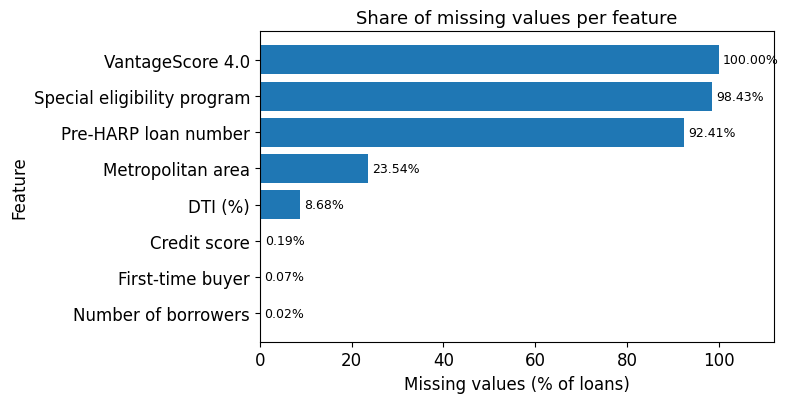

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display

NUMERIC_FEATURES = ["credit_score_classic_fico", "original_dti", "original_ltv", "original_upb",
                    "original_interest_rate", "mi_percent", "number_of_units", "number_of_borrowers",
                    "original_loan_term"]
CATEGORICAL_FEATURES = ["first_time_homebuyer_indicator", "occupancy_status", "channel", "property_type",
                        "loan_purpose", "property_state", "super_conforming_flag"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Freddie Mac codes for "not available" (user guide)
NUMERIC_CODES = {"credit_score_classic_fico": 9999, "vantage_score_4_0": 9999, "original_dti": 999,
                 "original_ltv": 999, "original_cltv": 999, "mi_percent": 999,
                 "number_of_units": 99, "number_of_borrowers": 99}
CATEGORICAL_CODES = {"first_time_homebuyer_indicator": "9", "occupancy_status": "9", "channel": "9",
                     "loan_purpose": "9", "property_type": "99"}


def show(title, table):
    # Print a title and the table, rounded to 4 decimals
    print(f"\n{title}")
    if isinstance(table, pd.Series):
        table = table.to_frame()
    display(table.round(4))


FIG_DIR = BASE_DIR + "figures/"
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 11})

def finish_plot(ax, title, xlabel, ylabel, file=None):
    # Every figure has a title and named axes, and is saved at 300 dpi when a file name is given
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    if file:
        plt.savefig(FIG_DIR + file + ".png", dpi=300, bbox_inches="tight")
    plt.show()

# Readable names for the figures instead of column names
NICE = {"credit_score_classic_fico": "Credit score", "original_dti": "DTI (%)", "original_ltv": "LTV (%)",
        "original_cltv": "Combined LTV (%)", "original_upb": "Loan amount", "original_interest_rate": "Interest rate (%)",
        "mi_percent": "Mortgage insurance (%)", "number_of_units": "Number of units",
        "number_of_borrowers": "Number of borrowers", "original_loan_term": "Loan term (months)",
        "vantage_score_4_0": "VantageScore 4.0", "special_eligibility_program": "Special eligibility program",
        "pre_harp_loan_sequence_number": "Pre-HARP loan number", "msa_or_metropolitan_division": "Metropolitan area",
        "first_time_homebuyer_indicator": "First-time buyer"}

for col, code in NUMERIC_CODES.items():
    df[col] = df[col].replace(code, np.nan)
for col in CATEGORICAL_FEATURES:
    text = df[col].astype(str).str.replace(r"\.0$", "", regex=True)      # "9.0" -> "9"
    df[col] = text.replace({CATEGORICAL_CODES.get(col, "no code"): np.nan, "nan": np.nan})

missing = df.isna().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)
show(f"Columns with missing values: {len(missing)} (% of loans)", missing.rename("% missing"))

shown = missing[missing >= 0.01].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.4 * len(shown) + 1))
bars = ax.barh(shown.index.map(lambda c: NICE.get(c, c)), shown.values)
ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)
ax.set_xlim(0, shown.max() * 1.12)
finish_plot(ax, "Share of missing values per feature", "Missing values (% of loans)", "Feature", file="missing_data")

In [4]:
# Size of the table and the type of each feature
show("Data type of each feature", df[FEATURES].dtypes.astype(str).rename("type"))

# The first five loans
show("First five loans", df[FEATURES + [TARGET, YEAR]].head())


Data type of each feature


,type
credit_score_classic_fico,float64
original_dti,float64
original_ltv,float64
original_upb,int64
original_interest_rate,float64
mi_percent,float64
number_of_units,float64
number_of_borrowers,float64
original_loan_term,int64
first_time_homebuyer_indicator,object



First five loans


,credit_score_classic_fico,original_dti,original_ltv,original_upb,original_interest_rate,mi_percent,number_of_units,number_of_borrowers,original_loan_term,first_time_homebuyer_indicator,occupancy_status,channel,property_type,loan_purpose,property_state,super_conforming_flag,DEFAULT_FLAG,sample_vintage_year
0,618.0,24.0,85.0,122000,6.375,25.0,1.0,2.0,317,N,P,R,SF,N,OH,N,0,1999
1,619.0,25.0,74.0,107000,5.250,0.0,1.0,2.0,180,N,P,R,SF,N,OH,N,0,1999
2,515.0,32.0,78.0,232000,6.250,0.0,1.0,2.0,313,N,S,R,SF,P,MA,N,0,1999
3,649.0,46.0,95.0,157000,6.750,NaN,1.0,1.0,360,Y,P,T,SF,P,CO,N,1,1999
4,768.0,21.0,75.0,111000,6.750,0.0,1.0,2.0,360,N,P,R,SF,C,MI,N,0,1999


In [5]:
# Count, mean, standard deviation, minimum, quartiles and maximum per numeric feature
show("Summary of the numeric features", df[NUMERIC_FEATURES].describe().T)


Summary of the numeric features


,count,mean,std,min,25%,50%,75%,max
credit_score_classic_fico,1097958.0,739.9881,52.8587,300.00,705.000,751.0,782.00,850.0
original_dti,1004512.0,33.6211,11.0890,1.00,26.000,34.0,42.00,65.0
original_ltv,1099957.0,71.4915,18.9082,3.00,61.000,75.0,80.00,684.0
original_upb,1100000.0,193401.0418,113000.8723,9000.00,109000.000,167000.0,253000.00,1397000.0
original_interest_rate,1100000.0,5.2162,1.3855,1.75,4.125,5.0,6.25,13.9
mi_percent,1099981.0,4.5451,9.9489,0.00,0.000,0.0,0.00,55.0
number_of_units,1099925.0,1.0288,0.2213,1.00,1.000,1.0,1.00,4.0
number_of_borrowers,1099805.0,1.5659,0.4986,1.00,1.000,2.0,2.00,5.0
original_loan_term,1100000.0,311.8963,78.3405,30.00,240.000,360.0,360.00,513.0


In [6]:
# How many loans fall in each category (missing values counted as their own category)
for col in CATEGORICAL_FEATURES:
    counts = df[col].value_counts(dropna=False)
    print(f"\n{col}: {counts.size} categories")
    show(f"Number of loans per category: {col}", counts.head(10).rename("loans"))


first_time_homebuyer_indicator: 3 categories

Number of loans per category: first_time_homebuyer_indicator


,loans
first_time_homebuyer_indicator,
N,970927
Y,128320
NaN,753



occupancy_status: 3 categories

Number of loans per category: occupancy_status


,loans
occupancy_status,
P,989106
I,66830
S,44064



channel: 5 categories

Number of loans per category: channel


,loans
channel,
R,609538
T,237674
C,185748
B,66991
NaN,49


... (4 outputs left out)


property_state: 54 categories

Number of loans per category: property_state


,loans
property_state,
CA,134246
TX,64907
FL,63687
IL,57465
MI,43706
OH,42239
NY,39797
PA,36280
NC,34821



super_conforming_flag: 2 categories

Number of loans per category: super_conforming_flag


,loans
super_conforming_flag,
N,1080224
Y,19776


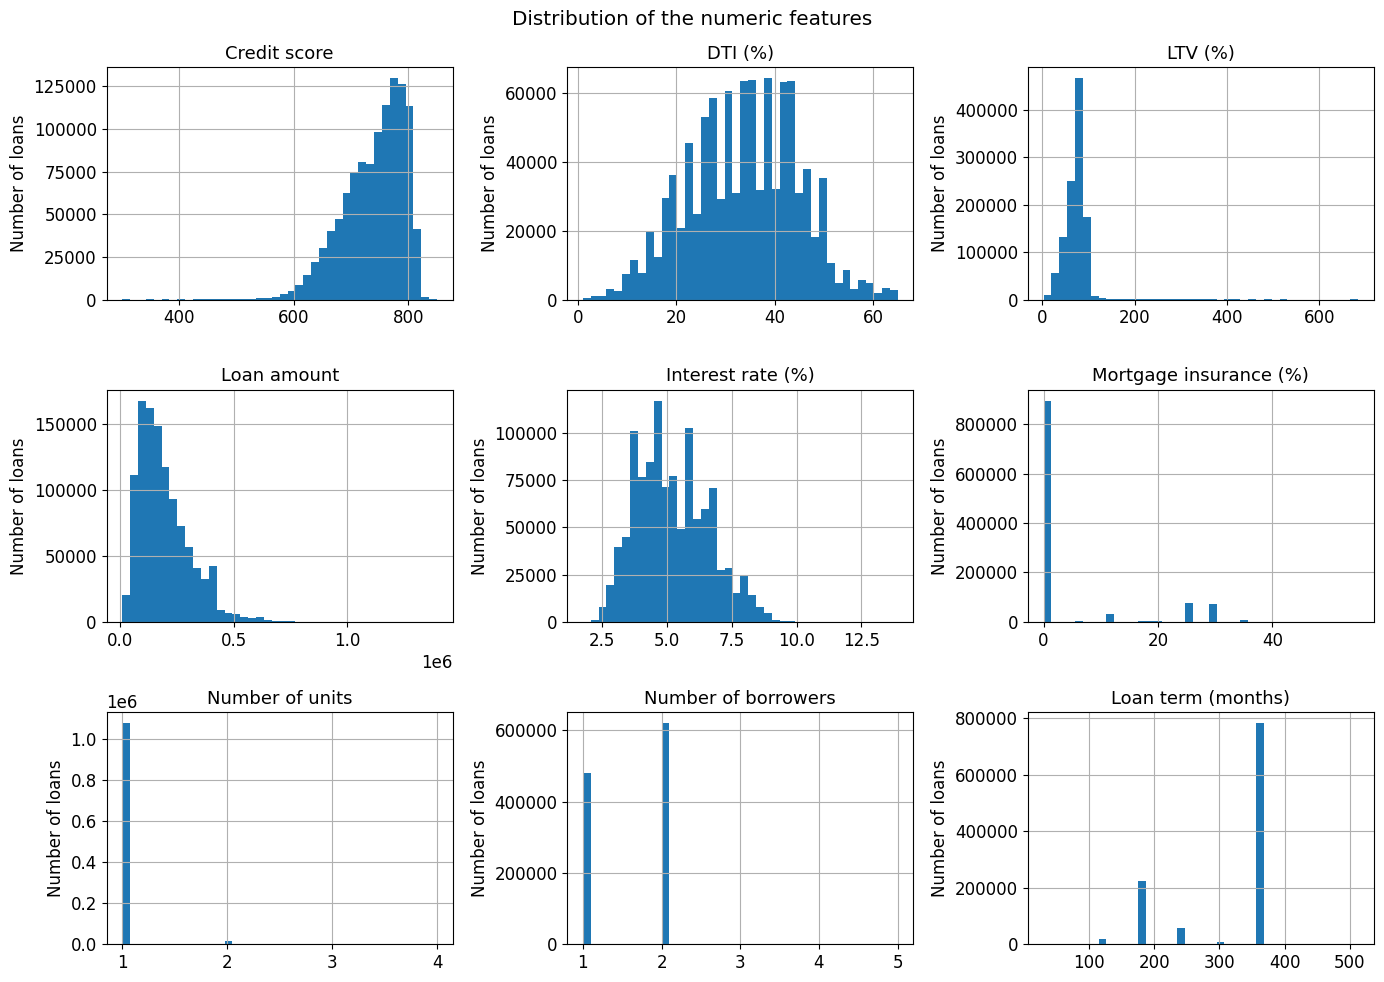

In [7]:
# One histogram per numeric feature
axes = df[NUMERIC_FEATURES].rename(columns=NICE).hist(bins=40, figsize=(14, 10), layout=(3, 3))
for ax in axes.flatten():
    ax.set_ylabel("Number of loans")
plt.suptitle("Distribution of the numeric features")
plt.tight_layout()
plt.savefig(FIG_DIR + "feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
# Default rate within 60 months per category, largest categories first
for col in ["occupancy_status", "loan_purpose", "channel", "first_time_homebuyer_indicator", "property_type"]:
    rates = df.groupby(col, dropna=False)[TARGET].agg(loans="size", default_rate="mean")
    show(f"Default rate by {col}", rates.sort_values("loans", ascending=False))


Default rate by occupancy_status


,loans,default_rate
occupancy_status,,
P,989106,0.0405
I,66830,0.0443
S,44064,0.0302



Default rate by loan_purpose


,loans,default_rate
loan_purpose,,
P,428586,0.0406
N,398792,0.0319
C,272619,0.0523
NaN,3,0.0000



Default rate by channel


,loans,default_rate
channel,,
R,609538,0.0336
T,237674,0.0647
C,185748,0.0324
B,66991,0.0373
NaN,49,0.0408



Default rate by first_time_homebuyer_indicator


,loans,default_rate
first_time_homebuyer_indicator,,
N,970927,0.0388
Y,128320,0.0523
NaN,753,0.0252



Default rate by property_type


,loans,default_rate
property_type,,
SF,807225,0.0409
PU,206430,0.0358
CO,78163,0.0439
MH,5863,0.0877
CP,2253,0.0209
NaN,66,0.0152


## 1.3 Linked files, duplicates and follow-up

Checks that every loan in the performance file has an origination record, that there are no duplicate loans, and that no loan appears in two origination years (which would leak from training into testing). `records_per_loan` shows how long loans are followed on average.

In [9]:
show("File checks per origination year",
     file_checks[["orig_loans", "perf_loans", "in_perf_not_in_orig", "in_orig_not_in_perf",
                  "records_per_loan"]])

ids_in_several_years = (df.groupby("loan_identifier")[YEAR].nunique() > 1).sum()


File checks per origination year


,orig_loans,perf_loans,in_perf_not_in_orig,in_orig_not_in_perf,records_per_loan
vintage,,,,,
1999,50000,50000,0,0,50.1
2000,50000,50000,0,0,28.9
2001,50000,50000,0,0,39.5
2002,50000,50000,0,0,49.9
2003,50000,50000,0,0,81.6
2004,50000,50000,0,0,79.7
2005,50000,50000,0,0,77.5
2006,50000,50000,0,0,64.1
2007,50000,50000,0,0,60.2


## 1.4 Outliers and plausibility

Unusual values are checked against the rules of the market instead of being deleted: credit scores must lie between 300 and 850, LTV above 100% is allowed for HARP refinances, very large loans are allowed in expensive areas (super conforming), and mortgage insurance should mainly appear above 80% LTV.

In [10]:
# A value is an outlier if it lies more than 1.5 x the middle range (IQR) outside it
for col in ["credit_score_classic_fico", "original_dti", "original_ltv", "original_upb", "original_interest_rate"]:
    values = df[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    n_outliers = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()
    print(f"{col:28s} outliers {n_outliers:7,}   range {values.min():g} to {values.max():g}")

fico = df["credit_score_classic_fico"]
print(f"\nCredit scores outside 300-850: {((fico < 300) | (fico > 850)).sum():,}")

ltv_over_100 = df[df["original_ltv"] > 100]
print(f"Loans with LTV above 100%: {len(ltv_over_100):,}, "
      f"of which HARP: {(ltv_over_100['harp_indicator'] == 'Y').mean():.1%}")

q1, q3 = df["original_upb"].quantile([0.25, 0.75])
large = df[df["original_upb"] > q3 + 1.5 * (q3 - q1)]
print(f"Unusually large loans: {len(large):,}, "
      f"of which super conforming: {(large['super_conforming_flag'] == 'Y').mean():.1%}")

print(f"Mean mortgage insurance coverage: {df.loc[df['original_ltv'] <= 80, 'mi_percent'].mean():.2f}% "
      f"for LTV <= 80, {df.loc[df['original_ltv'] > 80, 'mi_percent'].mean():.2f}% for LTV > 80")

credit_score_classic_fico    outliers   7,999   range 300 to 850
original_dti                 outliers     180   range 1 to 65
original_ltv                 outliers  52,962   range 3 to 684
original_upb                 outliers  24,189   range 9000 to 1.397e+06
original_interest_rate       outliers     924   range 1.75 to 13.9

Credit scores outside 300-850: 0
Loans with LTV above 100%: 16,328, of which HARP: 100.0%
Unusually large loans: 24,189, of which super conforming: 69.9%
Mean mortgage insurance coverage: 0.07% for LTV <= 80, 20.89% for LTV > 80


## 1.5 Correlations

Pairs with high correlation carry almost the same information.

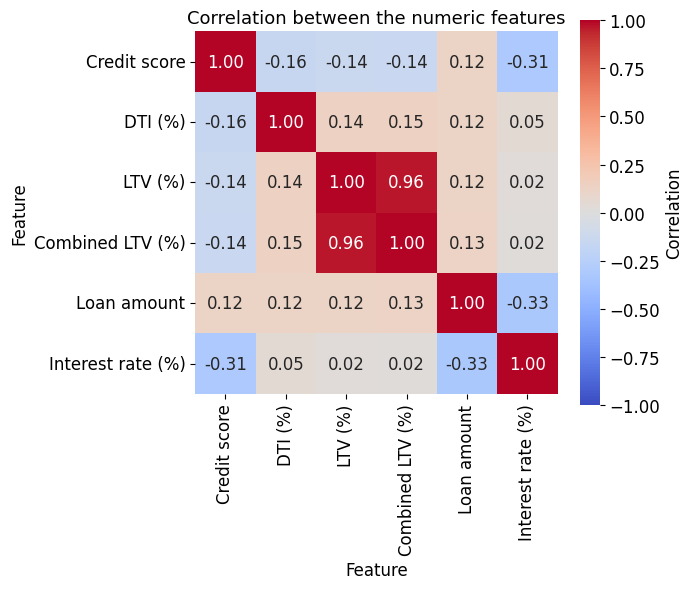

In [11]:
import seaborn as sns

corr = df[["credit_score_classic_fico", "original_dti", "original_ltv", "original_cltv",
           "original_upb", "original_interest_rate"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
corr = corr.rename(index=NICE, columns=NICE)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Correlation"})
finish_plot(ax, "Correlation between the numeric features", "Feature", "Feature", file="correlation_map")

## 1.6 Leakage: why some columns are never features

A column leaks if it holds information not known when the loan is made, or if it reveals the origination year. Excluded: the performance fields (only used for the label), `n_performance_months`, `harp_indicator`, `property_valuation_method`, the origination year, loan IDs and dates. The two tables show that HARP and the valuation method mark the origination period rather than borrower risk.

In [12]:
show("Share of HARP loans per origination year",
     df.groupby(YEAR)["harp_indicator"].apply(lambda s: (s == "Y").mean()).rename("harp_share"))
show("Property valuation method per origination year (7 = not available)",
     pd.crosstab(df[YEAR], df["property_valuation_method"].fillna("missing")))


Share of HARP loans per origination year


,harp_share
sample_vintage_year,
1999,0.0000
2000,0.0000
2001,0.0000
2002,0.0000
2003,0.0000
2004,0.0000
2005,0.0000
2006,0.0000
2007,0.0000



Property valuation method per origination year (7 = not available)


property_valuation_method,1,2,7
sample_vintage_year,,,
1999,0,0,50000
2000,0,0,50000
2001,0,0,50000
2002,0,0,50000
2003,0,0,50000
2004,0,0,50000
2005,0,0,50000
2006,0,0,50000
2007,0,0,50000


## 1.7 The default label: rate per year, timing and combined risk

- The overall default rate, and how many non-defaults there are per default (this sets the class weights in 2.1).
- The default rate per origination year.
- When defaults happen over the full loan life: the share of eventual defaults within the first 60 months supports the 60-month window.
- The highest-risk combination (credit score below 620, LTV above 97%, DTI above 50%), used in the Introduction as an illustration only.

Defaults: 44,382 of 1,100,000 loans (4.03%); 23.8 non-defaults per default

Default rate within 60 months per origination year


,loans,defaults,default_rate
sample_vintage_year,,,
1999,50000,1229,0.0246
2000,50000,1401,0.0280
2001,50000,1124,0.0225
2002,50000,936,0.0187
2003,50000,810,0.0162
2004,50000,1712,0.0342
2005,50000,3411,0.0682
2006,50000,5460,0.1092
2007,50000,6892,0.1378


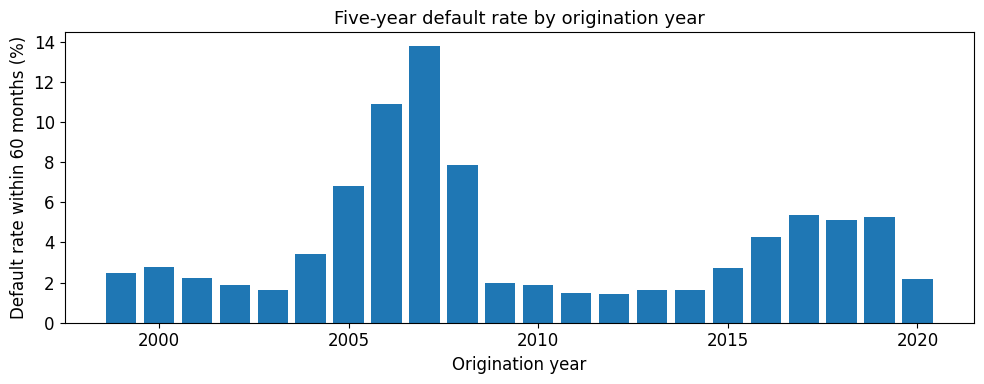

Share of eventual defaults within the first 60 months: 71.17% (median time to default 38 months)
Check: 44,382 defaults within 60 months here, 44,382 in DEFAULT_FLAG (should match)

Credit score <620, LTV >97% and DTI >50%: 38 loans, default rate 63.16%


In [13]:
n_defaults = int(df[TARGET].sum())
print(f"Defaults: {n_defaults:,} of {len(df):,} loans ({df[TARGET].mean():.2%}); "
      f"{(len(df) - n_defaults) / n_defaults:.1f} non-defaults per default")

by_year = df.groupby(YEAR)[TARGET].agg(loans="size", defaults="sum", default_rate="mean")
show("Default rate within 60 months per origination year", by_year)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_year.index, by_year["default_rate"] * 100)
finish_plot(ax, "Five-year default rate by origination year", "Origination year", "Default rate within 60 months (%)", file="default_percentage_per_year")

within_60 = first_default["months_to_default"] <= HORIZON_MONTHS
print(f"Share of eventual defaults within the first 60 months: {within_60.mean():.2%} "
      f"(median time to default {first_default['months_to_default'].median():.0f} months)")
print(f"Check: {within_60.sum():,} defaults within 60 months here, {n_defaults:,} in DEFAULT_FLAG (should match)")

riskiest = df[(df["credit_score_classic_fico"] < 620) & (df["original_ltv"] > 97) & (df["original_dti"] > 50)]
print(f"\nCredit score <620, LTV >97% and DTI >50%: {len(riskiest)} loans, "
      f"default rate {riskiest[TARGET].mean():.2%}")

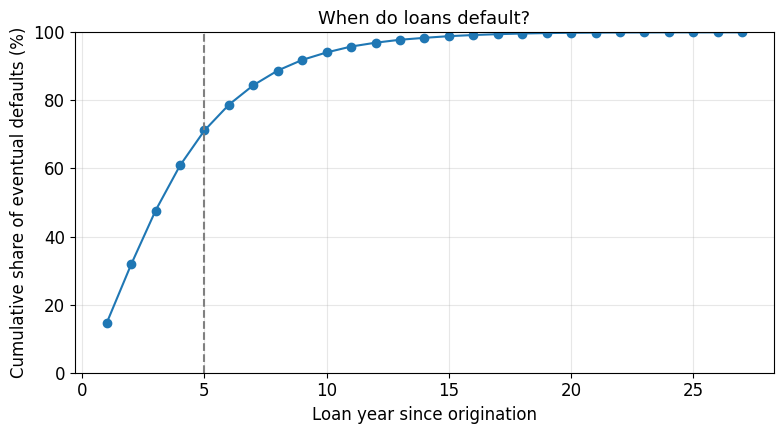

Share by year 5: 71.17%


In [14]:
# Cumulative share of eventual defaults by loan year (supports the 60-month window)
loan_year = np.ceil(first_default["months_to_default"] / 12).clip(lower=1)
cumulative = loan_year.value_counts().sort_index().cumsum() / len(loan_year) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cumulative.index, cumulative.values, marker="o")
ax.axvline(HORIZON_MONTHS / 12, color="grey", ls="--")
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)
finish_plot(ax, "When do loans default?", "Loan year since origination", "Cumulative share of eventual defaults (%)", file="default_timing")
print(f"Share by year 5: {cumulative.loc[5]:.2f}%")

## 1.8 The modelling sample: loans with a known five-year outcome

A loan can only be called "no default" if it was followed for its full 60 months. Two groups are removed: loans without any performance record, and loans whose 60-month window runs past the end of the data (March 2026). A loan paid off early without defaulting counts as a non-default, as in any fixed-horizon label.

In [15]:
DATA_END = "2026-03"                     # last month in the performance files (Release 47)

data = df[FEATURES + [TARGET, YEAR, "first_payment_date", "n_performance_months"]].copy()
first_payment = pd.to_datetime(data["first_payment_date"].astype(int).astype(str), format="%Y%m")
window_end = first_payment + pd.DateOffset(months=HORIZON_MONTHS - 1)

no_records = data["n_performance_months"] == 0
incomplete = window_end > pd.Timestamp(DATA_END)
print(f"Removed: {no_records.sum():,} loans without records, {incomplete.sum():,} with an incomplete window")

data = data[~no_records & ~incomplete].reset_index(drop=True)
print(f"{len(data):,} loans kept, default rate {data[TARGET].mean():.2%}")

Removed: 1,285 loans without records, 37 with an incomplete window
1,098,678 loans kept, default rate 4.04%


---
# Part 2. Models

## 2.1 Preprocessing and the four models

**Preprocessing** (learned on the training data of each test year only, then applied to validation and test data):
- numbers: missing values filled with the training median, plus a 0/1 "was missing" flag (a missing DTI can itself signal risk); standardised for logistic regression only;
- categories: one-hot encoded, with "Missing" as its own category; a category never seen in training gets all zeros.

**Class weights:** defaults get more weight, in inverse proportion to how rare they are, so both classes count equally in total. XGBoost has no "balanced" option, so the same ratio is passed as `scale_pos_weight`.

**Early stopping (XGBoost and LightGBM):** trees are added until the AUC on a 10% slice of the *training* data stops improving for 100 trees. The validation data are kept for tuning, calibration and the cutoff.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb

RANDOM_STATE = 42    # the seed: makes every random step repeatable


# ---------- Preprocessing: learned on the training data only ----------
def make_preprocessor(name):
    # Numbers: missing values get the training median, plus a 0/1 "was missing" column
    numeric_steps = [SimpleImputer(strategy="median", add_indicator=True)]
    # Logistic regression only: scale every number to mean 0 and sd 1, because its penalty treats all coefficients alike
    if name == "Logistic Regression":
        numeric_steps.append(StandardScaler())
    # Categories: missing becomes "Missing", then one 0/1 column per category
    categorical_steps = [SimpleImputer(strategy="constant", fill_value="Missing"),
                         OneHotEncoder(handle_unknown="ignore", sparse_output=False)]
    return ColumnTransformer([("num", make_pipeline(*numeric_steps), NUMERIC_FEATURES),
                              ("cat", make_pipeline(*categorical_steps), CATEGORICAL_FEATURES)],
                             verbose_feature_names_out=False)


# ---------- Training one model ----------
def fit(name, params, train, seed=RANDOM_STATE, class_weights=True):
    # Fits the preprocessing and the model on the training data; returns both as a pair
    X = train[FEATURES]
    y = train[TARGET].to_numpy()
    balanced = "balanced" if class_weights else None

    if name in ["XGBoost", "LightGBM"]:
        # Keep 10% of the training data aside to decide when to stop adding trees
        X, X_stop, y, y_stop = train_test_split(X, y, test_size=0.10, stratify=y, random_state=seed)

    prep = make_preprocessor(name)
    X = prep.fit_transform(X)

    if name == "Logistic Regression":
        # Logistic regression: a linear model on the log-odds scale with a tuned L2 penalty (C), defaults weighted to count as much as non-defaults
        model = LogisticRegression(max_iter=2000, class_weight=balanced, **params)
        model.fit(X, y)
    elif name == "Random Forest":
        # Random forest: 200 independent trees on random resamples of the loans, whose predictions are averaged
        model = RandomForestClassifier(n_estimators=200, class_weight=balanced, n_jobs=-1,
                                       random_state=seed, **params)
        model.fit(X, y)
    elif name == "XGBoost":
        # XGBoost: trees built one after another, each correcting the last, stopped when AUC on the 10% slice stops improving for 100 trees
        pos_weight = (y == 0).sum() / (y == 1).sum() if class_weights else 1.0
        model = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.01, subsample=0.5,
                                  scale_pos_weight=pos_weight, tree_method="hist", eval_metric="auc",
                                  early_stopping_rounds=100, n_jobs=-1, random_state=seed, **params)
        model.fit(X, y, eval_set=[(prep.transform(X_stop), y_stop)], verbose=False)
    else:
        # LightGBM: the same boosting idea as XGBoost, with tree size set by the tuned max_depth because num_leaves is left unlimited
        model = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.01, subsample=0.5,
                                   subsample_freq=1, num_leaves=1024, class_weight=balanced, n_jobs=-1,
                                   verbose=-1, random_state=seed, **params)
        model.fit(X, y, eval_set=[(prep.transform(X_stop), y_stop)], eval_metric="auc",
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    return prep, model


# ---------- Scoring new loans ----------
def predict(fitted, loans):
    # Raw model score (not yet calibrated) for each loan: P(default) from the second column
    prep, model = fitted
    return model.predict_proba(prep.transform(loans[FEATURES]))[:, 1]

## 2.2 Evaluation metrics

| Metric | Question | Computed on |
|---|---|---|
| ROC-AUC, PR-AUC | Does the model rank risky loans above safe ones? | raw scores |
| Brier score, ECE, observed vs predicted default rate | Are the probabilities right? | calibrated probabilities |
| Recall, false-negative rate, precision, false-positive rate | How many defaults are caught at the cutoff, and at what cost? | calibrated probabilities |

- **ECE** uses 10 groups of equal size (sorted by predicted probability), because with equal-width bins almost every loan would fall in the first bin.
- **Cutoff:** the one that maximises F2 on the validation data (recall counts twice as much as precision). For the robustness check, two more cutoffs limit the false-positive rate on the validation data to 10% and 5%.
- **Confidence interval:** 95% percentile bootstrap of test ROC-AUC (200 resamples of the test loans).

In [17]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve

N_BOOTSTRAP = 200        # resamples for the 95% confidence interval of test ROC-AUC
ECE_BINS = 10            # equal-size groups for the expected calibration error


def ece(y, p):
    # Sort loans by predicted probability, cut them into 10 groups of equal size,
    # and average |observed default rate - mean predicted probability| over the groups
    # https://scikit-learn.org/stable/modules/generated/sklearn.calibration.calibration_curve.html
    groups = np.array_split(np.argsort(p, kind="mergesort"), ECE_BINS)
    return sum(len(g) / len(p) * abs(y[g].mean() - p[g].mean()) for g in groups)


def f2_cutoff(y, p):
    # The cutoff with the highest F2 score
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.fbeta_score.html
    precision, recall, cutoffs = precision_recall_curve(y, p)
    f2 = 5 * precision * recall / np.maximum(4 * precision + recall, 1e-12)
    return cutoffs[np.argmax(f2[:-1])]


def max_fpr_cutoff(y, p, max_fpr):
    # The lowest cutoff that flags at most max_fpr of the non-defaults
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html
    values, counts = np.unique(p[y == 0], return_counts=True)
    share_flagged = np.cumsum(counts[::-1])[::-1] / (y == 0).sum()   # non-defaults at or above each value
    allowed = values[share_flagged <= max_fpr]
    return allowed[0] if len(allowed) > 0 else np.inf


def bootstrap_ci(y, p):
    # Resample the test loans with replacement and take the 2.5% and 97.5% percentiles of the AUCs
    # https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html
    # https://numpy.org/doc/stable/reference/generated/numpy.percentile.html
    rng = np.random.default_rng(RANDOM_STATE)
    aucs = []
    for _ in range(N_BOOTSTRAP):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():          # both classes needed
            aucs.append(roc_auc_score(y[i], p[i]))
    return np.percentile(aucs, [2.5, 97.5])


def evaluate(y, p_raw, p, cutoff):
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html
    flagged = p >= cutoff
    tp = int((flagged & (y == 1)).sum())
    fp = int((flagged & (y == 0)).sum())
    fn = int((~flagged & (y == 1)).sum())
    tn = int((~flagged & (y == 0)).sum())
    recall = tp / max(tp + fn, 1)
    return {"roc_auc": roc_auc_score(y, p_raw), "pr_auc": average_precision_score(y, p_raw),
            "brier": brier_score_loss(y, p), "ece": ece(y, p),
            "default_rate": y.mean(), "mean_predicted": p.mean(),
            "recall": recall, "fn_rate": 1 - recall, "precision": tp / max(tp + fp, 1),
            "fpr": fp / max(fp + tn, 1), "cutoff": cutoff, "tn": tn, "fp": fp, "fn": fn, "tp": tp}

## 2.3 Borrower-risk groups (used in RQ2 and RQ4)

Credit score (<660, 660-719, 720-779, 780+), LTV (≤80, 80-95, >95) and DTI (≤36, 36-43, >43). The cut-offs follow underwriting rules, not data quantiles: credit-score pricing tiers, the 80% LTV threshold for mortgage insurance, and the 43% DTI limit of the Qualified Mortgage rule. An LTV of exactly 80 belongs to "<=80" and a DTI of exactly 43 to "36-43".

In [18]:
RAW_COLUMNS = ["credit_score_classic_fico", "original_ltv", "original_dti"]    # the three risk factors
BANDS = ["credit_band", "ltv_band", "dti_band"]                                 # their banded versions
PAIRS = [["credit_band", "ltv_band"], ["ltv_band", "dti_band"], ["credit_band", "dti_band"]]   # the three pairs in RQ2
BAND_NAMES = {"credit_band": "Credit score band", "ltv_band": "LTV band (%)", "dti_band": "DTI band (%)"}   # axis labels


def add_bands(loans):
    loans = loans.copy()
    # Credit score: pricing tiers, with right=False so that 660 falls in "660-719" (300 to 850 is the valid range)
    loans["credit_band"] = pd.cut(loans["credit_score_classic_fico"], [300, 660, 720, 780, 851], right=False,
                                  labels=["<660", "660-719", "720-779", "780+"])
    # LTV: 80% is the threshold above which mortgage insurance is required, so 80 itself falls in "<=80"
    loans["ltv_band"] = pd.cut(loans["original_ltv"], [0, 80, 95, np.inf], labels=["<=80", "80-95", ">95"])
    # DTI: 43% is the Qualified Mortgage limit, so 43 itself falls in "36-43"
    loans["dti_band"] = pd.cut(loans["original_dti"], [0, 36, 43, np.inf], labels=["<=36", "36-43", ">43"])
    # A loan with a missing value gets its own group "Missing" instead of being dropped
    for band in BANDS:
        loans[band] = loans[band].cat.add_categories("Missing").fillna("Missing")
    return loans

## 2.4 SHAP values (used in RQ4)

SHAP splits a prediction into the push of each feature (Lundberg & Lee, 2017). It explains the raw score (log-odds), before calibration.
- **Logistic regression:** the SHAP value is exactly coefficient × (the loan's value − the training mean).
- **XGBoost and LightGBM:** TreeSHAP, built into both libraries (Lundberg et al., 2020).

One-hot columns are added back together, so `property_state` is one feature. Missing-value flags are kept as separate features.

In [19]:
# ============================================================
# 2.4 SHAP VALUES (used in RQ4)
# ============================================================

SHAP_SAMPLE = 1000       # test loans per year explained with SHAP

def explain(fitted, train, test, seed):
    prep, model = fitted
    # Take a random sample of 1,000 test loans and prepare them exactly as the model sees them
    sample = test.sample(min(SHAP_SAMPLE, len(test)), random_state=seed)
    X = prep.transform(sample[FEATURES])

    if isinstance(model, LogisticRegression):
        # Logistic regression: the exact SHAP value is coefficient x (the loan's value - the training mean)
        train_mean = prep.transform(train[FEATURES]).mean(axis=0)
        values = model.coef_[0] * (X - train_mean)
    elif isinstance(model, xgb.XGBClassifier):
        # XGBoost: built-in TreeSHAP, using only the trees early stopping kept; the last column (the average score) is dropped
        values = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True,
                                             iteration_range=(0, model.best_iteration + 1))[:, :-1]
    else:  # LightGBM
        # LightGBM: built-in TreeSHAP; the last column (the average score) is dropped
        values = model.predict(X, pred_contrib=True)[:, :-1]

    # Add the one-hot columns of each feature back together (allowed because SHAP values add up),
    # so that e.g. the ~50 state columns become one "property_state" value; missing-value flags stay separate
    names = list(prep.get_feature_names_out())
    shap = {}
    for f in FEATURES:
        columns = [i for i, n in enumerate(names) if n == f or n.startswith(f + "_")]
        shap[f] = values[:, columns].sum(axis=1)
        if "missingindicator_" + f in names:
            shap[f + " (missing flag)"] = values[:, names.index("missingindicator_" + f)]

    # Return the SHAP values together with each loan's raw credit score, LTV and DTI and its three bands (for RQ4 by group)
    raw = sample[RAW_COLUMNS].reset_index(drop=True)
    return pd.concat([pd.DataFrame(shap), raw.add_prefix("raw_"), add_bands(raw)[BANDS]], axis=1)

## 2.5 One experiment: one model, one test year

`run()` does everything for one model and one test year *T*. The main results and all robustness checks use this same function.

1. **Split.** Loans originated in *T*−1 are split at random (stratified) into 80% training and 20% validation data. All loans originated in *T* are the test data.
2. **Tune.** Every grid combination is fitted on the training data; the one with the highest validation ROC-AUC is kept. (Skipped when `params` is given, as in the robustness checks.)
3. **Calibrate.** Class weights push the raw scores up, so isotonic regression fitted on the validation data turns them back into default probabilities.
4. **Cutoff.** F2-optimal on the calibrated validation probabilities.
5. **Test.** Score the untouched test year. The test year is never used for tuning, early stopping, calibration or the cutoff.

With `extras=True` (main run only) it also returns the confidence interval, the results at the two other cutoffs, the test predictions (for RQ2) and SHAP values for a sample of test loans (for RQ4).

In [20]:
from sklearn.model_selection import ParameterGrid
from sklearn.isotonic import IsotonicRegression

# Settings tried in the grid search; every combination is fitted and the best on validation ROC-AUC is kept
PARAM_GRID = {
    "Logistic Regression": {"C": [0.001, 0.01, 0.1, 1.0, 100.0]},                                            # penalty strength (small C = strong penalty)
    "Random Forest":       {"max_features": ["sqrt", 0.25], "min_samples_leaf": [1, 25, 50, 100]},                 # 1 = default
    "XGBoost":             {"max_depth": [2, 3, 5, 6], "reg_lambda": [0, 1, 10]},                                  # 6 = default
    "LightGBM":            {"max_depth": [-1, 2, 3, 5], "min_child_samples": [20, 100, 1000], "reg_lambda": [0, 10]},  # -1 and 20 = defaults
}

def split(test_year, seed=RANDOM_STATE, window=1):
    # Development data = the year(s) before the test year, split 80/20 into training and validation with the same default rate;
    # test data = all loans of the test year
    development = data[data[YEAR].between(test_year - window, test_year - 1)]
    train, val = train_test_split(development, test_size=0.20, stratify=development[TARGET], random_state=seed)
    test = data[data[YEAR] == test_year]
    return train, val, test


def tune(name, train, val, seed):
    # Grid search: keep the settings with the highest validation ROC-AUC
    best_auc, best_params, best_fitted = -1, None, None
    for params in ParameterGrid(PARAM_GRID[name]):
        fitted = fit(name, params, train, seed)
        auc = roc_auc_score(val[TARGET], predict(fitted, val))
        if auc > best_auc:
            best_auc, best_params, best_fitted = auc, params, fitted
    return best_params, best_fitted


def run(test_year, name, params=None, seed=RANDOM_STATE, window=1, class_weights=True, extras=False):
    # 1-2. Split, then tune (or use the given settings)
    # (params is only given in the robustness checks, which reuse the settings of the main run)
    train, val, test = split(test_year, seed, window)
    if params is None:
        params, fitted = tune(name, train, val, seed)
    else:
        fitted = fit(name, params, train, seed, class_weights)

    # 3-4. Calibrate on the validation data and choose the cutoff there
    # Isotonic regression maps raw scores to the default rate actually seen at that score, without changing their order;
    # the cutoff is the one with the highest F2 on the calibrated validation probabilities
    y_val = val[TARGET].to_numpy()
    p_val_raw = predict(fitted, val)
    calibrator = IsotonicRegression(out_of_bounds="clip").fit(p_val_raw, y_val)
    p_val = calibrator.predict(p_val_raw)
    cutoff = f2_cutoff(y_val, p_val)

    # 5. Test
    # Score the untouched test year with the same model, calibrator and cutoff, and store all metrics in one row of results
    y = test[TARGET].to_numpy()
    p_raw = predict(fitted, test)
    p = calibrator.predict(p_raw)
    row = {"year": test_year, "model": name, "params": str(params), **evaluate(y, p_raw, p, cutoff),
           "train_auc": roc_auc_score(train[TARGET], predict(fitted, train)),
           "val_auc": roc_auc_score(y_val, p_val_raw),
           "val_default_rate": y_val.mean()}
    if not extras:
        return row, None, None

    # Extras for the main run
    # 95% bootstrap interval of the test ROC-AUC (for the RQ3 figure)
    row["auc_ci_low"], row["auc_ci_high"] = bootstrap_ci(y, p_raw)
    # Recall, precision and false-positive rate at two stricter cutoffs (for the cutoff robustness check)
    for label, max_fpr in [("fpr10", 0.10), ("fpr5", 0.05)]:
        other = evaluate(y, p_raw, p, max_fpr_cutoff(y_val, p_val, max_fpr))
        row[f"recall_{label}"] = other["recall"]
        row[f"precision_{label}"] = other["precision"]
        row[f"fpr_{label}"] = other["fpr"]
    # Every test loan with its label, scores, flag and bands (for RQ2)
    preds = add_bands(test[RAW_COLUMNS]).assign(
        y=y, p_raw=p_raw, p=p, pred=(p >= cutoff).astype(int), year=test_year, model=name)
    # SHAP values for 1,000 test loans (for RQ4); random forest is not explained
    shap = None
    if name != "Random Forest":
        shap = explain(fitted, train, test, seed).assign(year=test_year, model=name)
    return row, preds, shap

## 2.6 Main run: all models, all test years

Runs `run()` for every test year and model. This is the slow part (32 model fits per test year for the tuning). The results stay in memory: `results` (one row per test year and model), `predictions` (every test loan) and `shap_long` (SHAP values).

In [21]:
# ============================================================
# 2.6 MAIN RUN: ALL MODELS, ALL TEST YEARS
# ============================================================

MODELS = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM"]
TEST_YEARS = VINTAGES[1:]                # 2000-2020: each predicted by models developed on the year before

# Run one full experiment (split, tune, calibrate, cutoff, test) for every test year and model: 21 x 4 = 84 runs
rows, pred_parts, shap_parts = [], [], []
for year in TEST_YEARS:
    print(f"\n=== Test year {year} (developed on {year - 1}) ===")
    for name in MODELS:
        row, preds, shap = run(year, name, extras=True)
        rows.append(row)              # the metrics of this run
        pred_parts.append(preds)      # every test loan of this run
        if shap is not None:          # random forest has no SHAP values
            shap_parts.append(shap)
        # Progress line: test ROC-AUC with its 95% interval, calibration error, recall and the chosen settings
        print(f"  {name:20s} AUC {row['roc_auc']:.3f} [{row['auc_ci_low']:.3f}, {row['auc_ci_high']:.3f}]"
              f"  ECE {row['ece']:.4f}  recall {row['recall']:.3f}  {row['params']}")

# Stack the parts into the three tables that Part 3 reads
results = pd.DataFrame(rows)                                  # one row per test year and model (RQ1, RQ3)
predictions = pd.concat(pred_parts, ignore_index=True)        # one row per test loan and model (RQ2)
shap_long = pd.concat(shap_parts, ignore_index=True)          # one row per explained loan and model (RQ4)


=== Test year 2000 (developed on 1999) ===
  Logistic Regression  AUC 0.831 [0.819, 0.843]  ECE 0.0065  recall 0.708  {'C': 0.001}
  Random Forest        AUC 0.827 [0.815, 0.838]  ECE 0.0093  recall 0.700  {'max_features': 0.25, 'min_samples_leaf': 100}
  XGBoost              AUC 0.830 [0.818, 0.842]  ECE 0.0095  recall 0.717  {'max_depth': 2, 'reg_lambda': 10}
  LightGBM             AUC 0.829 [0.819, 0.841]  ECE 0.0092  recall 0.690  {'max_depth': 5, 'min_child_samples': 1000, 'reg_lambda': 10}

=== Test year 2001 (developed on 2000) ===
  Logistic Regression  AUC 0.855 [0.845, 0.865]  ECE 0.0069  recall 0.341  {'C': 0.01}
  Random Forest        AUC 0.841 [0.829, 0.852]  ECE 0.0045  recall 0.407  {'max_features': 0.25, 'min_samples_leaf': 100}
  XGBoost              AUC 0.849 [0.838, 0.860]  ECE 0.0055  recall 0.383  {'max_depth': 2, 'reg_lambda': 1}
  LightGBM             AUC 0.849 [0.838, 0.859]  ECE 0.0048  recall 0.379  {'max_depth': 2, 'min_child_samples': 20, 'reg_lambda': 0}



---
# Part 3. Answers to the research questions

## RQ1. Which model predicts best?

Mean and standard deviation of each metric over the test years. The best model on mean test ROC-AUC is used again in RQ2 and RQ4.

**Thesis:** `tab:model_comparison` (ROC-AUC, PR-AUC, train AUC, rank) and `tab:model_calibration` (Brier, ECE, recall, precision).

In [22]:
metrics = ["roc_auc", "pr_auc", "train_auc", "brier", "ece", "recall", "precision"]
show("RQ1 - mean over the test years", results.groupby("model")[metrics].mean().sort_values("roc_auc", ascending=False))
show("RQ1 - standard deviation over the test years", results.groupby("model")[metrics].std())

best_model = results.groupby("model")["roc_auc"].mean().idxmax()
print(f"\nBest model on mean test ROC-AUC: {best_model}")

# Mean ± SD over the test years, for the thesis tables
fmt = lambda m: (results.groupby("model")[m].mean().map("{:.3f}".format) + " ± "
                 + results.groupby("model")[m].std().map("{:.3f}".format))
show("RQ1 - mean ± SD over the test years", pd.DataFrame({m: fmt(m) for m in metrics}))


RQ1 - mean over the test years


,roc_auc,pr_auc,train_auc,brier,ece,recall,precision
model,,,,,,,
Logistic Regression,0.8056,0.1527,0.8215,0.0356,0.0109,0.5050,0.1334
LightGBM,0.8037,0.1528,0.8419,0.0355,0.0112,0.4931,0.1310
XGBoost,0.8026,0.1519,0.8377,0.0355,0.0110,0.4890,0.1313
Random Forest,0.7989,0.1467,0.8943,0.0357,0.0114,0.5033,0.1272



RQ1 - standard deviation over the test years


,roc_auc,pr_auc,train_auc,brier,ece,recall,precision
model,,,,,,,
LightGBM,0.0464,0.0944,0.0441,0.0247,0.0094,0.1774,0.0538
Logistic Regression,0.0455,0.0918,0.0442,0.0246,0.0086,0.1828,0.0560
Random Forest,0.0471,0.0891,0.0414,0.0250,0.0092,0.1914,0.0561
XGBoost,0.0466,0.0956,0.0442,0.0246,0.0090,0.1878,0.0574



Best model on mean test ROC-AUC: Logistic Regression

RQ1 - mean ± SD over the test years


,roc_auc,pr_auc,train_auc,brier,ece,recall,precision
model,,,,,,,
LightGBM,0.804 ± 0.046,0.153 ± 0.094,0.842 ± 0.044,0.036 ± 0.025,0.011 ± 0.009,0.493 ± 0.177,0.131 ± 0.054
Logistic Regression,0.806 ± 0.045,0.153 ± 0.092,0.822 ± 0.044,0.036 ± 0.025,0.011 ± 0.009,0.505 ± 0.183,0.133 ± 0.056
Random Forest,0.799 ± 0.047,0.147 ± 0.089,0.894 ± 0.041,0.036 ± 0.025,0.011 ± 0.009,0.503 ± 0.191,0.127 ± 0.056
XGBoost,0.803 ± 0.047,0.152 ± 0.096,0.838 ± 0.044,0.036 ± 0.025,0.011 ± 0.009,0.489 ± 0.188,0.131 ± 0.057


### Confusion matrices

For each model, the test loans of all years added up (each year uses its own cutoff). The percentage is the share of the actual class: for example, of all real defaults, how many were caught.

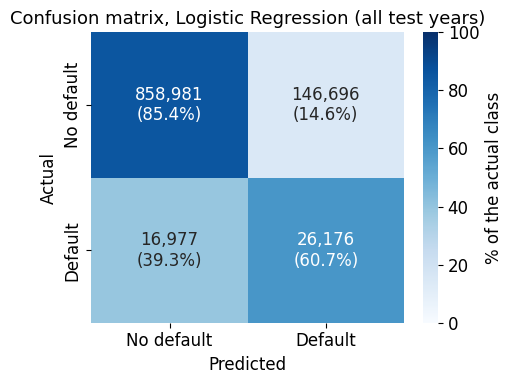

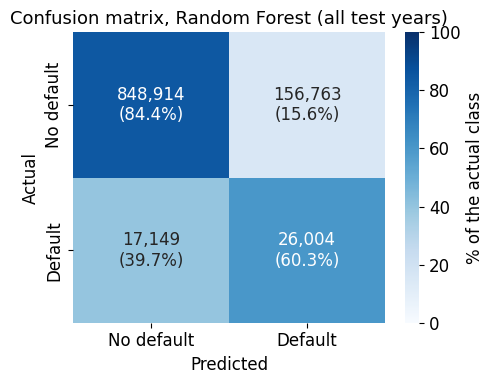

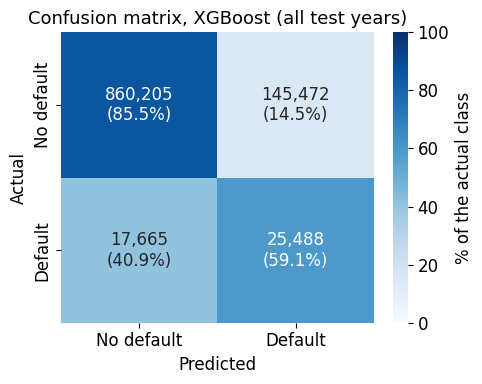

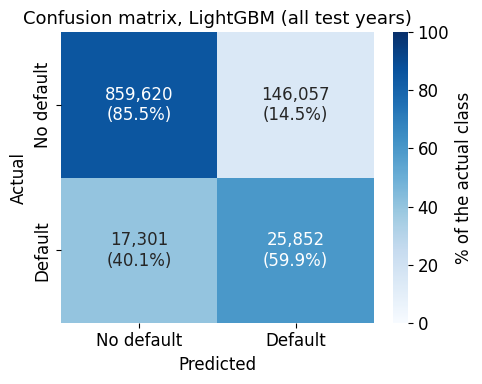

In [23]:
for name in MODELS:
    counts = results[results["model"] == name][["tn", "fp", "fn", "tp"]].sum()
    matrix = np.array([[counts["tn"], counts["fp"]], [counts["fn"], counts["tp"]]])
    share = matrix / matrix.sum(axis=1, keepdims=True) * 100
    labels = [[f"{matrix[i, j]:,}\n({share[i, j]:.1f}%)" for j in range(2)] for i in range(2)]
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(share, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=100, ax=ax,
                xticklabels=["No default", "Default"], yticklabels=["No default", "Default"],
                cbar_kws={"label": "% of the actual class"})
    finish_plot(ax, f"Confusion matrix, {name} (all test years)", "Predicted", "Actual", file="confusion_matrix_lr" if name == "Logistic Regression" else None)

### Is the ranking of the models consistent across years?

Following Demšar (2006): rank the models within each test year, test whether the average ranks differ (Friedman), then compare each pair (Wilcoxon signed-rank test, Holm correction for the six comparisons). Neighbouring years share economic conditions, so the p-values describe consistency, not formal proof.

The last table checks overfitting (train − validation AUC, same year) and the cost of moving to a new year (validation − test AUC).

In [24]:
# ============================================================
# RQ1: IS THE RANKING OF THE MODELS CONSISTENT ACROSS YEARS?
# ============================================================

from scipy.stats import friedmanchisquare, wilcoxon

# Reshape the 84 rows into a grid: one row per test year, one column per model, each cell a test ROC-AUC
auc = results.pivot(index="year", columns="model", values="roc_auc")[MODELS]    # test years x models
# Rank the four models within each year (1 = highest AUC), then average the ranks over the 21 years
show("RQ1 - average rank by ROC-AUC (1 = best)",
     auc.rank(axis=1, ascending=False).mean().sort_values().rename("average_rank"))

# Friedman test: do the average ranks differ more than chance would explain? (Demsar, 2006)
chi2, p_friedman = friedmanchisquare(*[auc[m] for m in MODELS])
print(f"\nFriedman test: chi2 = {chi2:.2f}, p = {p_friedman:.4f}")


def holm(p_values):
    # Holm correction: multiply the smallest p-value by 6, the next by 5, and so on,
    # and never let a corrected p-value be smaller than the one before it
    adjusted = np.empty(len(p_values))
    running_max = 0
    for rank, i in enumerate(np.argsort(p_values)):
        running_max = max(running_max, (len(p_values) - rank) * p_values[i])
        adjusted[i] = min(1, running_max)
    return adjusted


# Compare every pair of models (6 pairs): mean AUC difference, number of years A beats B,
# and a Wilcoxon signed-rank test on the 21 yearly differences
pair_rows = []
for i, a in enumerate(MODELS):
    for b in MODELS[i + 1:]:
        d = auc[a] - auc[b]                                        # 21 yearly differences
        pair_rows.append({"model_a": a, "model_b": b,
                          "mean_auc_difference": d.mean(),
                          "sd_difference": d.std(ddof=1),
                          "t_stat": d.mean() / (d.std(ddof=1) / np.sqrt(len(d))),   # effect size in standard errors
                          "years_a_better": (d > 0).sum(),
                          "p_wilcoxon": wilcoxon(auc[a], auc[b]).pvalue})
pairwise = pd.DataFrame(pair_rows)
# Correct the six p-values for making six comparisons at once
pairwise["p_holm"] = holm(pairwise["p_wilcoxon"].to_numpy())
show("RQ1 - pairwise comparison of the models", pairwise)

# Overfitting check: train - validation AUC (same year: memorising) and validation - test AUC (cost of a new year)
overfit = results.groupby("model")[["train_auc", "val_auc", "roc_auc"]].mean()
overfit["train_minus_val"] = overfit["train_auc"] - overfit["val_auc"]
overfit["val_minus_test"] = overfit["val_auc"] - overfit["roc_auc"]
show("RQ1 - overfitting and the drop to a new year", overfit)

# Validation AUC per model: mean and standard deviation over the 21 test years
results.groupby("model")["val_auc"].agg(["mean", "std"]).round(3)


RQ1 - average rank by ROC-AUC (1 = best)


,average_rank
model,
Logistic Regression,1.5714
LightGBM,2.1429
XGBoost,2.5238
Random Forest,3.7619



Friedman test: chi2 = 32.54, p = 0.0000

RQ1 - pairwise comparison of the models


,model_a,model_b,mean_auc_difference,sd_difference,t_stat,years_a_better,p_wilcoxon,p_holm
0,Logistic Regression,Random Forest,0.0068,0.0036,8.6683,20,0.0000,0.0000
1,Logistic Regression,XGBoost,0.0030,0.0057,2.4534,16,0.0127,0.0304
2,Logistic Regression,LightGBM,0.0019,0.0036,2.4881,15,0.0101,0.0304
3,Random Forest,XGBoost,-0.0037,0.0049,-3.4421,3,0.0012,0.0047
4,Random Forest,LightGBM,-0.0048,0.0034,-6.4986,1,0.0000,0.0000
5,XGBoost,LightGBM,-0.0011,0.0046,-1.1001,8,0.4319,0.4319



RQ1 - overfitting and the drop to a new year


,train_auc,val_auc,roc_auc,train_minus_val,val_minus_test
model,,,,,
LightGBM,0.8419,0.8157,0.8037,0.0262,0.0120
Logistic Regression,0.8215,0.8156,0.8056,0.0059,0.0100
Random Forest,0.8943,0.8095,0.7989,0.0847,0.0106
XGBoost,0.8377,0.8138,0.8026,0.0240,0.0112


,mean,std
model,,
LightGBM,0.816,0.045
Logistic Regression,0.816,0.043
Random Forest,0.810,0.044
XGBoost,0.814,0.044


## RQ2. How does performance differ across borrower-risk groups?

The test predictions of the best model are grouped by credit score, LTV and DTI (Section 2.3), alone and in pairs. Per group:
- **avg_yearly_auc:** ROC-AUC inside the group, per test year, then averaged. Only years with at least 50 loans and 10 defaults in the group count (`years_used`).
- **fn_rate:** share of the group's defaults that were missed. The cutoff is the same for every group.
- **calibration_gap:** observed − predicted default rate. Positive = risk underestimated.
- **adequate:** at least 50 loans and 10 defaults over all years.

In [25]:
MIN_LOANS, MIN_DEFAULTS = 50, 10   # a borrower group is only reported above this floor

def segment_table(preds, by):
    # Group the test loans by one band or a pair of bands (all test years pooled)
    groups = preds.groupby(by, observed=True)
    # Size of the group, actual default rate, and mean calibrated predicted probability
    table = pd.DataFrame({"n_loans": groups.size(),
                          "n_defaults": groups["y"].sum(),
                          "default_rate": groups["y"].mean(),
                          "predicted": groups["p"].mean()})
    # Observed - predicted: positive means the model underestimates the group's risk
    table["calibration_gap"] = table["default_rate"] - table["predicted"]
    # Among the group's defaulters only: the share NOT flagged at the cutoff (the same cutoff for every group in a year)
    table["fn_rate"] = 1 - preds[preds["y"] == 1].groupby(by, observed=True)["pred"].mean()
    table["fp_rate"] = preds[preds["y"] == 0].groupby(by, observed=True)["pred"].mean()

    # ROC-AUC inside the group, per test year (only when the group is big enough that year)
    def auc_if_enough(x):
        if len(x) >= MIN_LOANS and x["y"].sum() >= MIN_DEFAULTS and x["y"].nunique() == 2:
            return roc_auc_score(x["y"], x["p_raw"])
        return np.nan
    yearly = preds.groupby(by + ["year"], observed=True)[["y", "p_raw"]].apply(auc_if_enough)
    group_levels = list(range(len(by)))
    # Average the yearly AUCs per group, so that differences between years do not mix in; count the years used
    table["avg_yearly_auc"] = yearly.groupby(level=group_levels).mean()
    table["years_used"] = yearly.notna().groupby(level=group_levels).sum()
    # A group is adequate with at least 50 loans and 10 defaults over all years (smaller groups are blanked in the heatmaps)
    table["adequate"] = (table["n_loans"] >= MIN_LOANS) & (table["n_defaults"] >= MIN_DEFAULTS)
    return table


# Use the test predictions of the best model from RQ1 (logistic regression) only
best_preds = predictions[predictions["model"] == best_model]
# One table per single band and per pair of bands
rq2 = {}
for by in [["credit_band"], ["ltv_band"], ["dti_band"]] + PAIRS:
    key = " x ".join(by)
    rq2[key] = segment_table(best_preds, by)
    show(f"RQ2 - {key} ({best_model})", rq2[key])


RQ2 - credit_band (Logistic Regression)


,n_loans,n_defaults,default_rate,predicted,calibration_gap,fn_rate,fp_rate,avg_yearly_auc,years_used,adequate
credit_band,,,,,,,,,,
<660,84567,11795,0.1395,0.1214,0.0181,0.1287,0.6158,0.6668,21,True
660-719,242674,16444,0.0678,0.0608,0.0070,0.3323,0.2881,0.7115,21,True
720-779,422101,11649,0.0276,0.0255,0.0021,0.6195,0.0787,0.7516,21,True
780+,297832,3208,0.0108,0.0105,0.0003,0.8582,0.0130,0.7691,21,True
Missing,1656,57,0.0344,0.0465,-0.0121,0.4211,0.3508,0.7516,2,True



RQ2 - ltv_band (Logistic Regression)


,n_loans,n_defaults,default_rate,predicted,calibration_gap,fn_rate,fp_rate,avg_yearly_auc,years_used,adequate
ltv_band,,,,,,,,,,
<=80,823383,27707,0.0337,0.0300,0.0036,0.4544,0.1058,0.8004,21,True
80-95,189966,12257,0.0645,0.0586,0.0059,0.3054,0.2635,0.7575,21,True
>95,35442,3189,0.0900,0.0881,0.0019,0.2023,0.4877,0.7038,21,True
Missing,39,0,0.0000,0.0080,-0.0080,NaN,0.0769,NaN,0,False



RQ2 - dti_band (Logistic Regression)


,n_loans,n_defaults,default_rate,predicted,calibration_gap,fn_rate,fp_rate,avg_yearly_auc,years_used,adequate
dti_band,,,,,,,,,,
<=36,549276,14444,0.0263,0.0235,0.0028,0.5071,0.0773,0.8101,21,True
36-43,213557,10676,0.0500,0.0450,0.0050,0.3795,0.1941,0.7649,21,True
>43,192638,14080,0.0731,0.0628,0.0103,0.2951,0.2607,0.7520,21,True
Missing,93359,3953,0.0423,0.0470,-0.0047,0.3655,0.2172,0.7754,19,True


... (2 outputs left out)


RQ2 - ltv_band x dti_band (Logistic Regression)


n_loans  n_defaults  default_rate  predicted  calibration_gap  fn_rate  fp_rate  avg_yearly_auc  years_used  adequate
ltv_band dti_band                                                                                                                       
<=80     <=36       456217       10060        0.0221     0.0194           0.0026   0.5539   0.0577          0.8120          21      True
         36-43      161248        6850        0.0425     0.0379           0.0046   0.4340   0.1473          0.7684          21      True
         >43        153650        9309        0.0606     0.0537           0.0069   0.3549   0.2088          0.7445          21      True
         Missing     52268        1488        0.0285     0.0287          -0.0002   0.4973   0.1085          0.7810          17      True
80-95    <=36        87256        3883        0.0445     0.0415           0.0030   0.4110   0.1643          0.7581          21      True
         36-43       47403        3308        0.0698     0.0641           0.0056   0.3005   0.3197          0.7129          21      True
         >43         35449        4086        0.1153     0.0947           0.0205   0.1926   0.4583          0.7247          17      True
         Missing     19858         980        0.0494     0.0562          -0.0068   0.3735   0.2462          0.7100          13      True
>95      <=36         5777         501        0.0867     0.0709           0.0158   0.3134   0.3584          0.6956          11      True
         36-43        4901         518        0.1057     0.0922           0.0135   0.1641   0.5802          0.6888          10      True
         >43          3533         685        0.1939     0.1369           0.0570   0.0934   0.7149          0.6504          11      True
         Missing     21231        1485        0.0699     0.0837          -0.0138   0.2283   0.4690          0.6936           9      True
Missing  <=36           26           0        0.0000     0.0014          -0.0014      NaN   0.0000             NaN           0     False
         36-43           5           0        0.0000     0.0183          -0.0183      NaN   0.2000             NaN           0     False
         >43             6           0        0.0000     0.0112          -0.0112      NaN   0.1667             NaN           0     False
         Missing         2           0        0.0000     0.0589          -0.0589      NaN   0.5000             NaN           0     False


RQ2 - credit_band x dti_band (Logistic Regression)


n_loans  n_defaults  default_rate  predicted  calibration_gap  fn_rate  fp_rate  avg_yearly_auc  years_used  adequate
credit_band dti_band                                                                                                                       
<660        <=36        37094        4358        0.1175     0.0977           0.0198   0.1907   0.5090          0.6672          20      True
            36-43       18812        2736        0.1454     0.1228           0.0226   0.1283   0.6490          0.6389          19      True
            >43         18539        3504        0.1890     0.1554           0.0336   0.0705   0.7095          0.6617          18      True
            Missing     10122        1197        0.1183     0.1434          -0.0251   0.0744   0.7896          0.6308          17      True
660-719     <=36       108301        5155        0.0476     0.0423           0.0053   0.4776   0.1740          0.7105          21      True
            36-43       58232        4271        0.0733     0.0662           0.0072   0.3093   0.3472          0.6836          21      True
            >43         55473        5690        0.1026     0.0879           0.0147   0.2248   0.4203          0.6782          21      True
            Missing     20668        1328        0.0643     0.0692          -0.0050   0.3035   0.3918          0.6861          15      True
720-779     <=36       222676        3719        0.0167     0.0157           0.0010   0.7849   0.0269          0.7386          21      True
            36-43       88187        2958        0.0335     0.0310           0.0026   0.5997   0.1093          0.7122          21      True
            >43         79167        3962        0.0500     0.0439           0.0061   0.4826   0.1759          0.7033          21      True
            Missing     32071        1010        0.0315     0.0336          -0.0021   0.6059   0.1247          0.7275          14      True
780+        <=36       180107        1172        0.0065     0.0064           0.0001   0.9343   0.0028          0.7414          20      True
            36-43       48041         699        0.0146     0.0145           0.0001   0.8612   0.0166          0.7085          13      True
            >43         39213         919        0.0234     0.0217           0.0018   0.7780   0.0425          0.7181          15      True
            Missing     30471         418        0.0137     0.0141          -0.0004   0.8158   0.0305          0.7698          12      True
Missing     <=36         1098          40        0.0364     0.0428          -0.0064   0.4500   0.3261          0.7745           1      True
            36-43         285          12        0.0421     0.0498          -0.0077   0.3333   0.3883             NaN           0      True
            >43           246           5        0.0203     0.0599          -0.0396   0.4000   0.4274             NaN           0     False
            Missing        27           0        0.0000     0.0395          -0.0395      NaN   0.2593             NaN           0     False

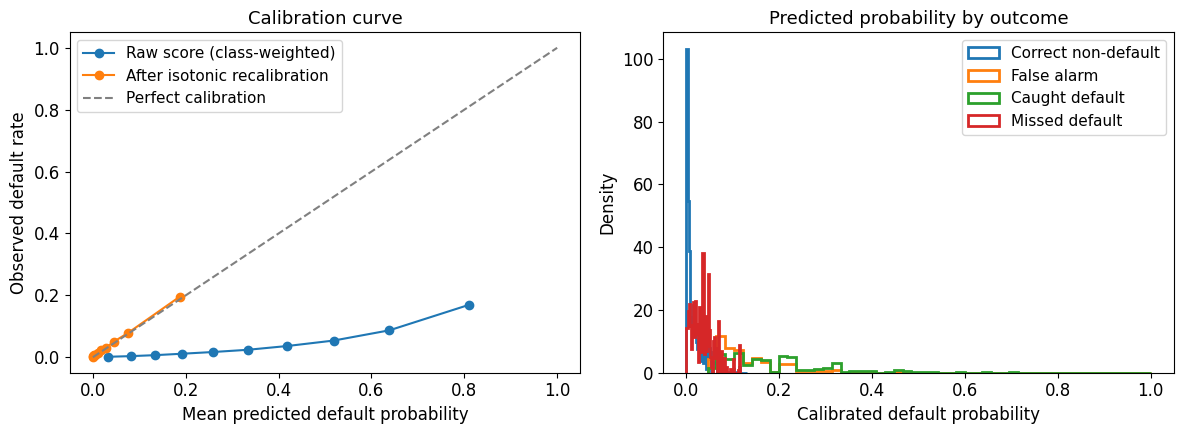


Median calibrated probability by outcome


,p
Caught default,0.1610
Correct non-default,0.0072
False alarm,0.1085
Missed default,0.0314


In [26]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: calibration curve, raw (class-weighted) score vs recalibrated probability
for col, label in [("p_raw", "Raw score (class-weighted)"), ("p", "After isotonic recalibration")]:
    observed, predicted = calibration_curve(best_preds["y"], best_preds[col], n_bins=10, strategy="quantile")
    axes[0].plot(predicted, observed, marker="o", label=label)
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", label="Perfect calibration")
axes[0].set(title="Calibration curve", xlabel="Mean predicted default probability", ylabel="Observed default rate")
axes[0].legend()

# Right: calibrated probability for each outcome type (prediction confidence)
outcome = np.select([(best_preds["y"] == 1) & (best_preds["pred"] == 1),
                     (best_preds["y"] == 0) & (best_preds["pred"] == 0),
                     (best_preds["y"] == 0) & (best_preds["pred"] == 1)],
                    ["Caught default", "Correct non-default", "False alarm"], "Missed default")
for name in ["Correct non-default", "False alarm", "Caught default", "Missed default"]:
    axes[1].hist(best_preds.loc[outcome == name, "p"], bins=50, density=True, histtype="step", linewidth=2, label=name)
axes[1].set(title="Predicted probability by outcome", xlabel="Calibrated default probability", ylabel="Density")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR + "calibration_confidence.png", dpi=300, bbox_inches="tight")
plt.show()

show("Median calibrated probability by outcome", best_preds.groupby(outcome)["p"].median())

### Heatmaps for the pairs of risk factors

One heatmap per pair and measure (ROC-AUC within the group, false-negative rate, calibration gap). Blank cells have fewer than 50 loans or 10 defaults.

**Thesis:** `fig:heatmaps`.

In [ ]:
# One entry per measure: (column in the RQ2 table, colour-bar label, colour map, lowest and highest colour value,
# multiplier, number format). The gap is multiplied by 100 to show percentage points.
MEASURES = [("avg_yearly_auc", "ROC-AUC within the group", "viridis", 0.5, 0.9, 1, ".2f"),
            ("fn_rate", "False-negative rate", "Reds", 0, 1, 1, ".2f"),
            ("calibration_gap", "Observed - predicted default rate (pp)", "RdBu_r", -15, 15, 100, "+.1f")]

# One heatmap per pair of risk factors and per measure: 3 pairs x 3 measures = 9 figures
for row_band, col_band in PAIRS:
    table = rq2[f"{row_band} x {col_band}"]
    for measure, label, cmap, vmin, vmax, scale, fmt in MEASURES:
        # Turn the table into a grid (rows = first band, columns = second band); groups below 50 loans or 10 defaults become blank
        grid = (table[measure].where(table["adequate"]) * scale).unstack()
        # Leave out the "Missing" groups
        grid = grid.drop(index="Missing", columns="Missing", errors="ignore")
        # Colour the grid and write the value in every cell
        fig, ax = plt.subplots(figsize=(6, 4.5))
        sns.heatmap(grid, annot=True, fmt=fmt, cmap=cmap, vmin=vmin, vmax=vmax, ax=ax, cbar_kws={"label": label})
        finish_plot(ax, f"{label}: {BAND_NAMES[row_band]} x {BAND_NAMES[col_band]} ({best_model})",
                    BAND_NAMES[col_band], BAND_NAMES[row_band])

### Do all four models struggle in the same groups?

The within-group ROC-AUC for every model and single risk factor. If all models score low in the same group, the difficulty lies in the data for that group, not in one model.

**Thesis:** RQ2 text ("all four models show the same pattern").

In [28]:
# Compute the within-group ROC-AUC for every model and every single band (credit score, LTV, DTI)
cross_rows = []
for name in MODELS:
    model_preds = predictions[predictions["model"] == name]
    for band in BANDS:
        table = segment_table(model_preds, [band])
        # Keep only groups with at least 50 loans and 10 defaults, and leave out "Missing"
        for group, r in table.iterrows():
            if r["adequate"] and group != "Missing":
                cross_rows.append({"factor": band, "group": group, "model": name, "auc": r["avg_yearly_auc"]})

# One row per group, one column per model
all_models = pd.DataFrame(cross_rows).pivot_table(index=["factor", "group"], columns="model", values="auc")[MODELS]
# Spread = best minus worst model in the group; a small spread means the difficulty lies in the data, not in one model
all_models["spread"] = all_models.max(axis=1) - all_models.min(axis=1)
show("RQ2 - within-group ROC-AUC, all models", all_models)
print(f"Largest difference between models in one group: {all_models['spread'].max():.3f}")


RQ2 - within-group ROC-AUC, all models


model                Logistic Regression  Random Forest  XGBoost  LightGBM  spread
factor      group                                                                 
credit_band 660-719               0.7115         0.7036   0.7066    0.7085  0.0079
            720-779               0.7516         0.7394   0.7459    0.7469  0.0122
            780+                  0.7691         0.7603   0.7704    0.7703  0.0101
            <660                  0.6668         0.6517   0.6585    0.6613  0.0151
dti_band    36-43                 0.7649         0.7567   0.7613    0.7635  0.0082
            <=36                  0.8101         0.8060   0.8093    0.8102  0.0043
            >43                   0.7520         0.7416   0.7448    0.7470  0.0104
ltv_band    80-95                 0.7575         0.7450   0.7514    0.7537  0.0124
            <=80                  0.8004         0.7947   0.7981    0.7992  0.0057
            >95                   0.7038         0.6856   0.6902    0.6893  0.0182

Largest difference between models in one group: 0.018


### The riskiest pair over time

Follows loans with credit score below 660 and DTI above 43% year by year, to see whether the underestimation is persistent or limited to some years (for example just before the 2008 crisis).

**Thesis:** RQ2 text ("about 8 percentage points in 2005, 2006 and 2007").

In [ ]:
risky = best_preds[(best_preds["credit_band"] == "<660") & (best_preds["dti_band"] == ">43")]
risky_by_year = risky.groupby("year").agg(n_loans=("y", "size"), n_defaults=("y", "sum"),
                                          observed=("y", "mean"), predicted=("p", "mean"))
risky_by_year["gap"] = risky_by_year["observed"] - risky_by_year["predicted"]
show("RQ2 - credit score <660 and DTI >43, by test year", risky_by_year)

In [ ]:
# ============================================================
# RQ2 CHECK: IS A GROUP'S GAP CAUSED BY THE GROUP, OR BY THE YEARS ITS LOANS COME FROM?
# ============================================================
# The gaps in Table 7 pool all test years together. If a group's loans come mostly from years in which
# the models underestimated ALL loans (e.g. 2005-2007), the group gap partly reflects those years.
# Split each pooled gap into two parts that add up exactly:
#   time part  = the all-loan gap of the years the group's loans come from (weighted by the group's loans per year)
#   group part = how much more the group is underestimated than all loans in the same year

# The five groups of Table 7
CHECK_GROUPS = {
    "LTV >95 and DTI >43":     lambda d: (d["ltv_band"] == ">95") & (d["dti_band"] == ">43"),
    "Credit <660 and DTI >43": lambda d: (d["credit_band"] == "<660") & (d["dti_band"] == ">43"),
    "Credit <660 and LTV 80-95": lambda d: (d["credit_band"] == "<660") & (d["ltv_band"] == "80-95"),
    "Credit <660 and LTV >95": lambda d: (d["credit_band"] == "<660") & (d["ltv_band"] == ">95"),
    "LTV <=80 and DTI <=36":   lambda d: (d["ltv_band"] == "<=80") & (d["dti_band"] == "<=36"),
}

# Gap over ALL test loans, per model and test year (observed minus mean calibrated prediction)
all_loans = predictions.groupby(["model", "year"]).agg(observed=("y", "mean"), predicted=("p", "mean"))
all_loans_gap = all_loans["observed"] - all_loans["predicted"]

check_rows = []
for group_name, condition in CHECK_GROUPS.items():
    for name in MODELS:
        part = predictions[(predictions["model"] == name) & condition(predictions)]
        # Per test year: size, observed and predicted default rate, and the group's gap
        yearly = part.groupby("year").agg(n_loans=("y", "size"), n_defaults=("y", "sum"),
                                          observed=("y", "mean"), predicted=("p", "mean"))
        yearly["gap"] = yearly["observed"] - yearly["predicted"]
        # The all-loan gap of the same model in the same year, and how much worse the group is
        yearly["all_loans_gap"] = all_loans_gap.loc[name].reindex(yearly.index)
        yearly["excess_gap"] = yearly["gap"] - yearly["all_loans_gap"]
        weights = yearly["n_loans"] / yearly["n_loans"].sum()
        # Years with enough loans and defaults (same floor as the rest of RQ2)
        enough = yearly[(yearly["n_loans"] >= MIN_LOANS) & (yearly["n_defaults"] >= MIN_DEFAULTS)]
        check_rows.append({"group": group_name, "model": name,
                           "pooled_gap": part["y"].mean() - part["p"].mean(),        # the number in Table 7
                           "time_part": (weights * yearly["all_loans_gap"]).sum(),
                           "group_part": (weights * yearly["excess_gap"]).sum(),     # time_part + group_part = pooled_gap
                           "year_avg_gap": enough["gap"].mean(),                    # each adequate year counts equally
                           "years_used": len(enough)})
        # Keep the year-by-year table of the main group for the best model
        if group_name == "LTV >95 and DTI >43" and name == best_model:
            show(f"RQ2 check - LTV >95 and DTI >43 by test year ({best_model})", yearly)

# All gaps in percentage points; one block per group, one row per model
check = pd.DataFrame(check_rows).set_index(["group", "model"])
gap_cols = ["pooled_gap", "time_part", "group_part", "year_avg_gap"]
check[gap_cols] = (check[gap_cols] * 100).round(2)
show("RQ2 check - pooled gap split into time part and group part (pp)", check)

# Side question: the LTV >95 loans with missing DTI (probably HARP refinances), by test year
harp_like = best_preds[(best_preds["ltv_band"] == ">95") & (best_preds["dti_band"] == "Missing")]
show("RQ2 check - LTV >95 with missing DTI, loans per test year", harp_like.groupby("year").size().to_frame("n_loans"))

## RQ3. How do accuracy and calibration change across origination years?

In every figure below, the shaded areas mark the cohorts whose five-year window covers the whole event year (2004-2008 for the 2008 crisis, 2016-2020 for the 2020 pandemic). The dashed line marks 2014, the first cohort under the ATR/QM rule. These are associations in time, not causal effects.

**Thesis:** `fig:annual_auc`.

In [ ]:
def mark_events(ax):
    for start, end, label in [(2004, 2008, "window covers 2008 crisis"), (2016, 2020, "window covers 2020 pandemic")]:
        ax.axvspan(start - 0.5, end + 0.5, color="grey", alpha=0.12)
        ax.text((start + end) / 2, ax.get_ylim()[1], label, fontsize=11, ha="center", va="top", color="dimgrey")
    ax.axvline(2013.5, color="grey", ls="--")
    ax.text(2013.6, ax.get_ylim()[0], " ATR/QM rule", fontsize=11, va="bottom", color="dimgrey")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))     # whole years on the axis
    ax.grid(alpha=0.3)


fig, ax = plt.subplots(figsize=(11, 5))
for name in MODELS:
    r = results[results["model"] == name].sort_values("year")
    line, = ax.plot(r["year"], r["roc_auc"], marker="o", label=name)
    ax.fill_between(r["year"], r["auc_ci_low"], r["auc_ci_high"], color=line.get_color(), alpha=0.1)
mark_events(ax)
ax.legend(loc="lower left")
finish_plot(ax, "Test ROC-AUC by origination year (95% bootstrap interval)",
            "Test origination year", "ROC-AUC", file="rq3_auc")

### Calibration per year

Each model is calibrated on the year before the test year. When the default rate jumps between the two years (`base_rate_shift`), the predictions lag behind, so the calibration gap should follow the base-rate shift.

**Thesis:** `fig:calibration`; RQ3 text on 2005, 2007, 2008 and 2020.

In [ ]:
# Per test year, averaged over the four models: actual default rate, default rate of the validation year (T-1),
# mean predicted probability and ECE
calib = results.groupby("year")[["default_rate", "val_default_rate", "mean_predicted", "ece"]].mean()
# Observed - predicted: positive means risk was underestimated
calib["calibration_gap"] = calib["default_rate"] - calib["mean_predicted"]
# Jump in the default rate from the calibration year (T-1) to the test year (T); the gap should follow this jump
calib["base_rate_shift"] = calib["default_rate"] - calib["val_default_rate"]
show("RQ3 - calibration by test year (mean over models)", calib)

# Figure 1: actual against mean predicted default rate per test year
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(calib.index, calib["default_rate"] * 100, marker="o", label="Observed")
ax.plot(calib.index, calib["mean_predicted"] * 100, marker="s", label="Mean predicted")
mark_events(ax)
ax.legend()
finish_plot(ax, "Observed and predicted default rate by test year (mean over models)",
            "Test origination year", "Five-year default rate (%)")

# Figure 2: ECE per test year, one line per model
fig, ax = plt.subplots(figsize=(11, 4.5))
for name in MODELS:
    r = results[results["model"] == name].sort_values("year")
    ax.plot(r["year"], r["ece"], marker="o", markersize=3, label=name)
mark_events(ax)
ax.legend()
finish_plot(ax, "Expected calibration error by test year", "Test origination year", "ECE")

### Results by period

The test years grouped into five periods, by the same rule as the shaded areas.

**Thesis:** `tab:eras`.

In [ ]:
# ============================================================
# RQ3: RESULTS BY PERIOD
# ============================================================

def period(year):
    # Assign each test year to one of five periods (the same rule as the shaded areas in the figures)
    if year <= 2003:
        return "1. 2000-2003"
    if year <= 2008:
        return "2. 2004-2008 (window covers the crisis)"
    if year <= 2013:
        return "3. 2009-2013 (after the crisis)"
    if year <= 2015:
        return "4. 2014-2015 (ATR/QM rule)"
    return "5. 2016-2020 (ATR/QM, window covers the pandemic)"


# Add the period and the calibration gap (observed - predicted) to every row of results
by_period = results.copy()
by_period["period"] = by_period["year"].apply(period)
by_period["calibration_gap"] = by_period["default_rate"] - by_period["mean_predicted"]
# Mean per period over all years and all four models together (tab:eras)
show("RQ3 - by period (mean over models)",
     by_period.groupby("period")[["default_rate", "roc_auc", "ece", "calibration_gap"]].mean())
# The same ROC-AUC per period, but separately for each model
show("RQ3 - ROC-AUC by period and model", by_period.pivot_table(index="period", columns="model", values="roc_auc"))

### Is a lower AUC the model's fault, or is the population changing?

Uses credit score alone as a "model" (no training). If its AUC falls in the same years as the fitted model, the drop comes from a changing borrower population: after the crisis fewer risky borrowers got loans, so borrowers became more alike and harder to rank.

**Thesis:** `fig:casemix`; RQ3 text; the 2020 share below 660 in "The 2020 default label".

In [ ]:
# Per test year: rank the loans by credit score alone (no model, no training) and describe the borrower mix
case_rows = []
for year in TEST_YEARS:
    # All loans of this origination year with a known credit score
    cohort = data[(data[YEAR] == year) & data["credit_score_classic_fico"].notna()]
    fico = cohort["credit_score_classic_fico"]
    case_rows.append({"year": year,
                      # Benchmark AUC: minus the score, so a lower score counts as riskier; it cannot become outdated
                      "credit_score_only_auc": roc_auc_score(cohort[TARGET], -fico),   # lower score = riskier
                      # Spread of credit scores: a smaller spread leaves less to rank on
                      "credit_score_sd": fico.std(),
                      # Share of the riskiest borrowers
                      "share_below_660": (fico < 660).mean(),
                      # Test ROC-AUC of the best model in the same year, for comparison
                      "model_auc": auc.loc[year, best_model]})
case_mix = pd.DataFrame(case_rows).set_index("year")
show(f"RQ3 - credit-score-only benchmark (model_auc = {best_model})", case_mix)

# Figure: if both lines fall together, the loans became harder to rank, not the model worse
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(case_mix.index, case_mix["model_auc"], marker="o", label=best_model)
ax.plot(case_mix.index, case_mix["credit_score_only_auc"], marker="s", label="Credit score only")
mark_events(ax)
ax.legend()
finish_plot(ax, f"ROC-AUC of {best_model} and of credit score alone", "Test origination year", "ROC-AUC", file="rq3_case_mix")

## RQ4. Which features drive the predictions?

Two models are explained: the best model from RQ1, and the best boosting model. Logistic regression can only treat groups differently through their feature values; a tree model can learn that a feature matters more in some groups. Comparing both shows whether the drivers really differ.

Mean |SHAP| is the average size of a feature's push on the prediction, whatever its direction, over a sample of test loans from every test year.

**Thesis:** `tab:shap_overall`; Explainability Analysis (the three focal years 2008, 2014 and 2020 are in the by-year tables).

In [35]:
# Pick the models to explain: the best model from RQ1 plus the booster with the higher mean ROC-AUC
best_booster = results[results["model"].isin(["XGBoost", "LightGBM"])].groupby("model")["roc_auc"].mean().idxmax()
EXPLAINED = [best_model, best_booster] if best_model in ["Logistic Regression"] + ["XGBoost", "LightGBM"] else [best_booster]
EXPLAINED = list(dict.fromkeys(EXPLAINED))        # removes a duplicate if the best model is the best booster
print("Explained models:", EXPLAINED)

# Keep only the SHAP values of those two models, and list the SHAP columns (everything except model, year, bands and raw values)
shap_long = shap_long[shap_long["model"].isin(EXPLAINED)]
SHAP_FEATURES = [c for c in shap_long.columns
                 if c not in ["model", "year"] + BANDS and not c.startswith("raw_")]

# Mean |SHAP| per feature and model over all explained loans: how much a feature moves the score, whatever the direction
importance = shap_long.groupby("model")[SHAP_FEATURES].apply(lambda d: d.abs().mean()).T
# Sort the features by their average importance over the two models
importance = importance.loc[importance.mean(axis=1).sort_values(ascending=False).index]
show("RQ4 - mean |SHAP|, all test years (log-odds scale)", importance)
# The eight most important features, used in the group tables below
TOP = list(importance.index[:8])

# Stability of the explanations: SD of the yearly mean |SHAP| across the 21 test years
yearly = shap_long.groupby(["model", "year"])[SHAP_FEATURES].apply(lambda d: d.abs().mean())
show("RQ4 - SD of mean |SHAP| across test years", yearly.groupby(level="model").std().T.loc[importance.index])

# Mean |SHAP| of the top five features per test year, per model (to see whether the drivers change over time)
for m in EXPLAINED:
    show(f"RQ4 - mean |SHAP| by test year, {m}",
         shap_long[shap_long["model"] == m].groupby("year")[TOP[:5]].apply(lambda d: d.abs().mean()))

Explained models: ['Logistic Regression', 'LightGBM']

RQ4 - mean |SHAP|, all test years (log-odds scale)


model,LightGBM,Logistic Regression
credit_score_classic_fico,0.6897,0.6075
original_ltv,0.3385,0.3342
number_of_borrowers,0.3251,0.3370
original_interest_rate,0.2435,0.2449
original_dti,0.2661,0.2076
property_state,0.1533,0.2448
loan_purpose,0.1246,0.1880
original_upb,0.1446,0.1185
original_loan_term,0.1052,0.1301
channel,0.0488,0.0808



RQ4 - SD of mean |SHAP| across test years


model,LightGBM,Logistic Regression
credit_score_classic_fico,0.1102,0.1024
original_ltv,0.1728,0.1940
number_of_borrowers,0.0786,0.0617
original_interest_rate,0.1433,0.1663
original_dti,0.0821,0.0582
property_state,0.1108,0.1374
loan_purpose,0.0998,0.1083
original_upb,0.0768,0.0774
original_loan_term,0.0537,0.0549
channel,0.0361,0.0538



RQ4 - mean |SHAP| by test year, Logistic Regression


,credit_score_classic_fico,original_ltv,number_of_borrowers,original_interest_rate,original_dti
year,,,,,
2000,0.7363,0.2563,0.2765,0.2414,0.1251
2001,0.6809,0.3035,0.2963,0.6068,0.2005
2002,0.7233,0.2201,0.3670,0.4113,0.1408
2003,0.6823,0.3806,0.3340,0.2830,0.1777
2004,0.7974,0.2563,0.2848,0.1498,0.2066
2005,0.7789,0.3444,0.3145,0.0709,0.1388
2006,0.6225,0.4534,0.2928,0.3569,0.1380
2007,0.6529,0.6145,0.3319,0.0828,0.1772
2008,0.6067,0.5934,0.3435,0.2205,0.2101



RQ4 - mean |SHAP| by test year, LightGBM


,credit_score_classic_fico,original_ltv,number_of_borrowers,original_interest_rate,original_dti
year,,,,,
2000,0.8384,0.2826,0.3040,0.2972,0.1549
2001,0.7302,0.2752,0.2194,0.2365,0.2147
2002,0.8227,0.2642,0.3378,0.3747,0.1218
2003,0.7218,0.4391,0.2583,0.1826,0.3122
2004,0.8110,0.2512,0.1826,0.1658,0.1651
2005,0.8800,0.3383,0.2788,0.1310,0.1333
2006,0.7284,0.3924,0.2616,0.3541,0.1696
2007,0.7242,0.5152,0.3335,0.0894,0.2454
2008,0.6966,0.5791,0.3523,0.1498,0.2681


### Do the drivers differ across the RQ2 groups?

For each credit score, LTV and DTI group (alone and in pairs): each feature's **share** of the total |SHAP| in that group, so groups with different overall risk can be compared. Groups with fewer than 30 explained loans, and "Missing" groups, are left out.

For logistic regression, the variable that defines the group is left out of its own comparison: there its SHAP value only measures the distance from the training mean, not importance.

**Thesis:** `tab:shap_groups`.

In [ ]:
# The feature that defines each band
BAND_FEATURE = {"credit_band": "credit_score_classic_fico", "ltv_band": "original_ltv", "dti_band": "original_dti"}

for m in ['Logistic Regression', 'LightGBM']:
    rows_m = shap_long[shap_long["model"] == m]
    # One table per single band and per pair of bands
    for by in [["credit_band"], ["ltv_band"], ["dti_band"]] + PAIRS:
        features = TOP
        # Logistic regression: leave out the feature that defines the group, because its SHAP value there
        # only measures the distance from the training mean, not importance
        if m == "Logistic Regression":
            features = [f for f in TOP if f not in [BAND_FEATURE[b] for b in by]]
        share_rows = []
        for group, part in rows_m.groupby(by, observed=True):
            # Skip groups with fewer than 30 explained loans (too noisy) and "Missing" groups
            if len(part) < 30 or "Missing" in np.atleast_1d(group):
                continue
            # Mean |SHAP| per feature in this group, then each feature's share of the group's total,
            # so that groups with different overall risk can be compared
            size = part[SHAP_FEATURES].abs().mean()
            share = size / size.sum()
            share_rows.append({"group": ", ".join(group), "n_loans": len(part), **share[features].to_dict()})
        show(f"RQ4 - share of |SHAP| by {' x '.join(by)}, {m}", pd.DataFrame(share_rows).set_index("group"))

### How DTI affects the prediction

Each explained loan's DTI against its DTI contribution, one figure per model, with a dashed line at the 43% QM limit. For logistic regression this is a straight line by construction; a tree model can bend. Loans with missing DTI are left out.

**Thesis:** `fig:dti`.

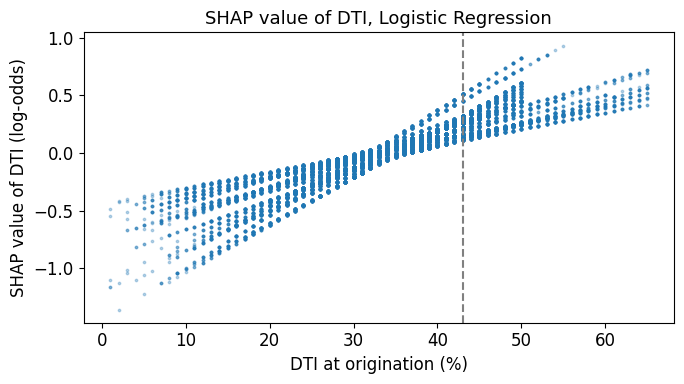

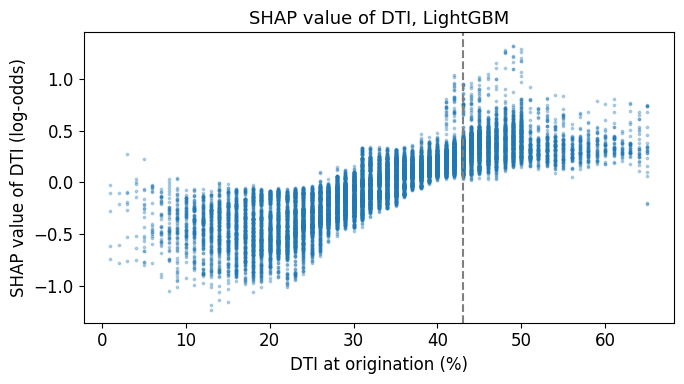

In [37]:
for m in EXPLAINED:
    rows_m = shap_long[(shap_long["model"] == m) & shap_long["raw_original_dti"].notna()]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(rows_m["raw_original_dti"], rows_m["original_dti"], s=3, alpha=0.3)
    ax.axvline(43, color="grey", ls="--")
    finish_plot(ax, f"SHAP value of DTI, {m}", "DTI at origination (%)", "SHAP value of DTI (log-odds)", file=f"rq4_dti_{m.replace(' ', '_')}")

## Robustness checks

All checks reuse the hyperparameters chosen in the main run, so any difference comes from the check itself and not from new tuning.

1. **Partitionings:** two more random 80/20 splits of each development year (seeds 7 and 123; the main run is seed 42). The seed also changes the early-stopping slice and the randomness inside the tree models.
2. **Training window:** two or three origination years instead of one, compared on the test years available for all three (2002 onwards).
3. **Cutoffs:** the F2 cutoff against cutoffs that limit the false-positive rate on the validation data to 10% and 5% (already computed in the main run).
4. **Class weights:** logistic regression fitted without class weights.

**Thesis:** `tab:partitionings`, `tab:window_comparison`, `tab:threshold_sensitivity`, Cutoff and class weights paragraph.

In [ ]:
import ast

# The settings chosen by the grid search in the main run, per test year and model.
# They are stored as text in results["params"]; ast.literal_eval turns "{'C': 0.01}" back into a dictionary.
# Reusing them means no new tuning: any difference comes from the check itself.
chosen = {(r.year, r.model): ast.literal_eval(r.params) for r in results.itertuples()}

robust_rows = []
for year in TEST_YEARS:
    print(f"Robustness checks, test year {year}")
    for name in MODELS:
        params = chosen[(year, name)]
        # Check 1, partitionings: a different random 80/20 split, early-stopping slice and tree randomness (seeds 7 and 123)
        for seed in [7, 123]:
            row, _, _ = run(year, name, params=params, seed=seed)
            robust_rows.append({**row, "check": f"seed {seed}"})
        # Check 2, training window: develop on the 2 or 3 years before the test year (only when those years exist)
        for window in [2, 3]:
            if year - window >= VINTAGES[0]:
                row, _, _ = run(year, name, params=params, window=window)
                robust_rows.append({**row, "check": f"{window}-year window"})
    # Check 4, class weights: logistic regression fitted without class weights
    row, _, _ = run(year, "Logistic Regression", params=chosen[(year, "Logistic Regression")], class_weights=False)
    robust_rows.append({**row, "check": "no class weights"})
    # (Check 3, cutoffs, needs no new runs: the main run already stored the results at the stricter cutoffs)

# Put the main run and all checks in one table, with a "check" column saying which run each row belongs to
robust = pd.concat([results.assign(check="main (seed 42, 1-year window)"), pd.DataFrame(robust_rows)],
                   ignore_index=True)

In [39]:
# 1. Three partitionings
seeds = robust[robust["check"].isin(["main (seed 42, 1-year window)", "seed 7", "seed 123"])]
by_seed = seeds.pivot_table(index="check", columns="model", values="roc_auc")[MODELS]
show("Robustness - mean test ROC-AUC per partitioning", by_seed)
show("Robustness - mean and SD over the three partitionings", by_seed.agg(["mean", "std"]))

# 2. Training window, on the test years that all three windows have
windows = robust[robust["check"].isin(["main (seed 42, 1-year window)", "2-year window", "3-year window"])]
windows = windows[windows["year"] >= VINTAGES[0] + 3]
windows["check"] = windows["check"].replace({"main (seed 42, 1-year window)": "1-year window"})
show("Robustness - ROC-AUC by training window", windows.pivot_table(index="model", columns="check", values="roc_auc"))
show("Robustness - ECE by training window", windows.pivot_table(index="model", columns="check", values="ece"))

# 3. Cutoffs, logistic regression (from the main run)
lr = results[results["model"] == "Logistic Regression"]
cutoff_table = pd.DataFrame({
    "false_positive_rate": [lr["fpr"].mean(), lr["fpr_fpr10"].mean(), lr["fpr_fpr5"].mean()],
    "recall": [lr["recall"].mean(), lr["recall_fpr10"].mean(), lr["recall_fpr5"].mean()],
    "precision": [lr["precision"].mean(), lr["precision_fpr10"].mean(), lr["precision_fpr5"].mean()]},
    index=["F2 cutoff", "FPR <= 10% on validation", "FPR <= 5% on validation"])
show("Robustness - logistic regression under different cutoffs", cutoff_table)

# 4. Class weights, logistic regression
weights = robust[(robust["model"] == "Logistic Regression")
                 & robust["check"].isin(["main (seed 42, 1-year window)", "no class weights"])]
show("Robustness - logistic regression with and without class weights",
     weights.groupby("check")[["roc_auc", "pr_auc", "brier", "ece", "recall", "precision"]].mean())

# Total running time of the whole notebook
total = time.time() - SCRIPT_START
print(f"\nTotal running time: {total / 60:.1f} minutes ({total / 3600:.2f} hours)")


Robustness - mean test ROC-AUC per partitioning


model,Logistic Regression,Random Forest,XGBoost,LightGBM
check,,,,
"main (seed 42, 1-year window)",0.8056,0.7989,0.8026,0.8037
seed 123,0.8048,0.7988,0.8029,0.8032
seed 7,0.8046,0.7985,0.8015,0.8001



Robustness - mean and SD over the three partitionings


model,Logistic Regression,Random Forest,XGBoost,LightGBM
mean,0.8050,0.7987,0.8024,0.8023
std,0.0005,0.0002,0.0007,0.0020



Robustness - ROC-AUC by training window


check,1-year window,2-year window,3-year window
model,,,
LightGBM,0.8000,0.8011,0.7993
Logistic Regression,0.8017,0.7997,0.7975
Random Forest,0.7952,0.7962,0.7954
XGBoost,0.7987,0.8009,0.7996


... (3 outputs left out)

,false_positive_rate,recall,precision
F2 cutoff,0.1487,0.5050,0.1334
FPR <= 10% on validation,0.0731,0.3645,0.1684
FPR <= 5% on validation,0.0346,0.2286,0.2043



Robustness - logistic regression with and without class weights


,roc_auc,pr_auc,brier,ece,recall,precision
check,,,,,,
"main (seed 42, 1-year window)",0.8056,0.1527,0.0356,0.0109,0.5050,0.1334
no class weights,0.8027,0.1524,0.0356,0.0113,0.5029,0.1345



Total running time: 240.2 minutes (4.00 hours)
